<a href="https://colab.research.google.com/github/Andres-0319/BURGOS_ANDR-S_PR-CTICA_3_PERCEPTR-N_INTELIGENCIA_ARTIFICIAL/blob/main/Burgos_Andr%C3%A9s_Pr%C3%A1ctica_3_EL_PERCEPTR%C3%93N.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Universidad Politécnica Salesiana**

# **Carrera de Computación**

# **Asignatura de Inteligencia Artificial**

## **Nombre:** Burgos Galarza Jorge Andrés
## **Fecha:** 20 de noviembre de 2026
## **Tema:** Práctica 03. El Perceptrón

**OBJETIVO:**

**1.** Comprender el funcionamiento del perceptrón como modelo básico de clasificación binaria.

**2.** Implementar manualmente la función de activación, la propagación hacia adelante y la regla de actualización de pesos.

**3.** Entrenar un perceptrón sin utilizar librerías de machine learning.

**4.** Visualizar la frontera de decisión generada por el perceptrón durante el proceso de entrenamiento.

**5.** Analizar la influencia de la tasa de aprendizaje en la convergencia del modelo.

**6.** Evaluar el comportamiento del modelo frente a nuevas instancias no utilizadas durante el entrenamiento.

## **ACTIVIDADES A DESARROLLAR:**
Antes de implementar un modelo neuronal, es necesario comprender que el perceptrón no es una “red neuronal”, sino una unidad de decisión lineal. Su objetivo es encontrar una frontera que separe dos clases mediante una combinación ponderada de entradas. En esta práctica trabajarás con un conjunto de puntos bidimensionales etiquetados con dos clases: -1 y 1. Tu tarea será implementar un perceptrón capaz de aprender una frontera de decisión para separar ambas clases.

# **Fase 1. Exploración del Dataset**

El perceptrón trabaja con datos numéricos. En este caso, cada instancia tiene dos variables de entrada: X1, X2 y una etiqueta de salida: y ∈ { −1, 1 }

## **1.1 Carga del Dataset**

Crear una matriz denominada X y un vector y con los siguientes datos:

In [20]:
# Ingreso de los datos de "X_1" y "X_2", donde cada sublista contiene dos valores
matriz_X = [[1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2], [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2], [4, 8], [6, 8], [8, 9], [9, 7], [10, 11],
           [12, 9], [12, 6], [14, 7], [16, 4]]
# Se crea la lista con la etiqueta de clase correspondiente a cada fila de la "matriz_X"
vector_y = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, +1, +1, +1, +1, +1, +1, +1, +1, +1]

# Se asignan las variables correspondientes para referciar la matriz de entrada y el vector de etiquetas
# Matriz de entradas
x = matriz_X
# Vector de Etiquetas
y = vector_y

### **Actividad 1.a — Inspección inicial**

Identifica los siguientes datos:
* Número total de instancias.
* Variables de entrada.
* Número de clases.
* Cantidad de puntos por clase.

No utilices librerías de análisis de datos. Puedes resolverlo con ciclos, contadores y listas.

**Pregunta guía:** ¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué este problema se considera de clasificación binaria?

In [21]:
# Número total de instancias
# Se inicializa el contador total de instancias (filas)
total_instancias = 0
# Se recorre cada fila dentro de la matriz_X empleando un bucle "for"
for fila in matriz_X:
  # Por cada instancia encontrada se incrementa el contador en 1
  total_instancias += 1


# Variables de entrada
# Inicializamos el contador de las variables de entrada (columnas por instancia)
variables_de_entrada = 0
# Verificamos que la matriz no esté vacia antes de consultar su primera fila
if total_instancias > 0:
  # Recorremos cada valor dentro de la primera fila para encontrar cuantas variables de entrada hay
  for valor in matriz_X[0]:
    # Se incrementa en 1 por cada "X_1" y "X_2"
    variables_de_entrada += 1

# Se crea una lista vacía para guardar las clases distintas que aparezcan en el vector_y
clases_unicas = []


# Número de clases
# Inicializamos el contador del número de clases
numero_clases = 0
# Recorremos cada etiqueta de clase dentro del vector_y
for etiqueta in vector_y:
  # Verificamos si esta etiqueta aún no ha sido registrada en clases únicas
  if etiqueta not in clases_unicas:
    # Agregamos la nueva clase a la lista de clases únicas
    clases_unicas.append(etiqueta)
    # Se incrementa el contador total de clases distintas
    numero_clases += 1


# Cantidad de puntos por clase
# Se cuenta las instacias con la etiqueta "-1"
puntos_clase_negativa = 0
# Se cuenta las instacias con la etiqueta "+1"
puntos_clase_positiva = 0
# Se recorré el vector "y" para contar cuantos puntos pertenecen a cada clase
for etiqueta in vector_y:
  # Si la etiqueta es -1, se suma al contador de la clase correspondiente
  if etiqueta == -1:
    puntos_clase_negativa += 1
  # Si la etiqueta es +1, se suma al contador de la clase correspondiente
  elif etiqueta == 1:
    puntos_clase_positiva += 1

# Se guarda la cantidad de puntos por clase en la variable correspondiente
cantidad_puntos_por_clase = {-1: puntos_clase_negativa, 1: puntos_clase_positiva}

# Se muestra los resultados correspondientes en pantalla
print("Numero total de instancias: ", total_instancias)
print("Variables de entrada: ", variables_de_entrada)
print("Numero de clases: ", numero_clases)
print("Cantidad de puntos por clase: ", cantidad_puntos_por_clase)

Numero total de instancias:  23
Variables de entrada:  2
Numero de clases:  2
Cantidad de puntos por clase:  {-1: 14, 1: 9}


**RESPUESTA A LA PREGUNTA GUÍA:** Cada fila de "X" representa una instancia individual del conjunto de datos en un plano bidimensional. Cada valor de "y" representa la etiqueta de la clase real asociada a la instancia ubicada en la misma posción de "X". Este problema se conoce como clasificación binaria porque el objetivo del modelo es asignar cada entrada a únicamente dos categorías o clases mutuamente excluyentes.

### **Actividad 1.b — Separación visual de las clases**

Crea una función que permita grafica los puntos en un plano cartesiano. Utiliza un marcador diferente para la clase -1 y para la clase 1. Puedes utilizar matplotlib para esta actividad. La gráfica debería mirarse similar a la siguiente figura.

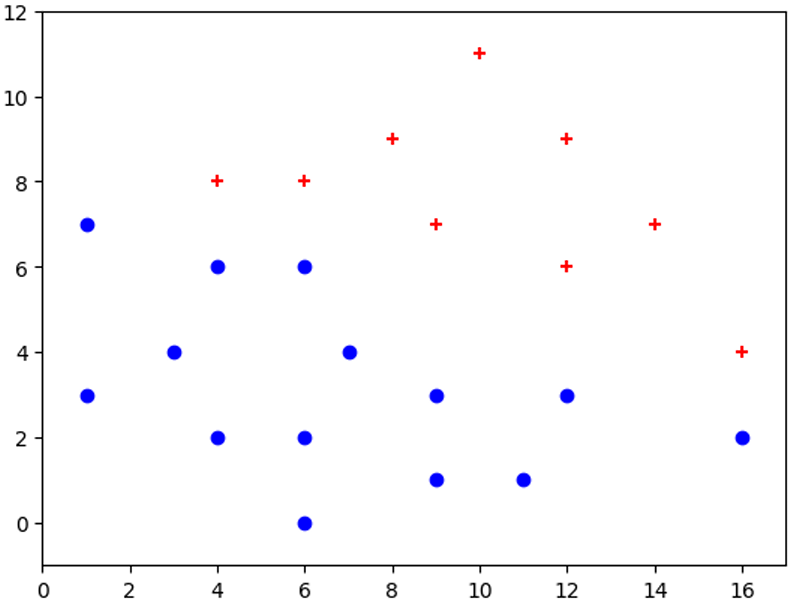

**Pregunta guía:** Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.

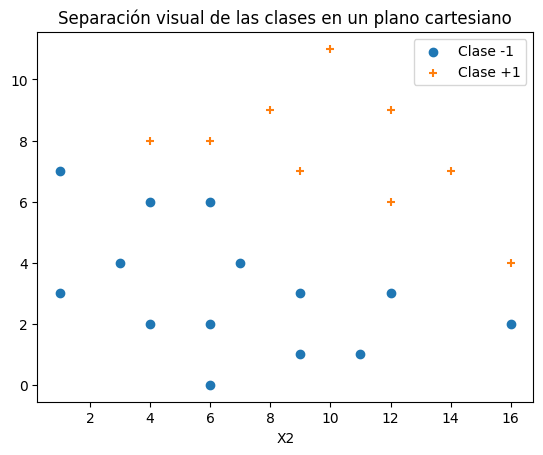

In [22]:
# Importacion de la librería
import matplotlib.pyplot as plt


# Se defina una función que grafique las instancias de "X" según su etiqueta en "y"
def graficar_clases(X, y):
  # Creamos las listas vacías para almacenar las coordenadas "X_1" y "X_2" de la clase "-1"
  x1_clase_negativa = []
  x2_clase_negativa = []
  # Creamos las listas vacías para almacenar las coordenadas "X_1" y "X_2" de la clase "+1"
  x1_clase_positiva = []
  x2_clase_positiva = []
  # Se recorre todas las instancias usando un índice de 0 hasta la longitud de "X-1"
  for i in range(len(X)):
    # Se obtiene el valor de "X1" de la instancia "i"
    x1 = X[i][0]
    # Se obtiene el valor de "X2" de la instancia "i"
    x2 = X[i][1]
    # Se obtiene la etiqueta real de la clase asociada a la instancia "i"
    etiqueta = y[i]
    # Si la etiqueta es "-1", se guarda "X1" y "X2" en las listas de la clase negativa
    if etiqueta == -1:
      x1_clase_negativa.append(x1)
      x2_clase_negativa.append(x2)
    # Si la etiqueta es "+1", se guarda "X1" y "X2" en las listas de la clase positiva
    elif etiqueta == 1:
      x1_clase_positiva.append(x1)
      x2_clase_positiva.append(x2)
  # Se crea una nueva figura para la gráfica
  plt.figure()
  # Graficamos los puntos de la clase -1 con marcador circular ('o') y etiqueta en la leyenda
  plt.scatter(x1_clase_negativa, x2_clase_negativa, marker='o', label = 'Clase -1')
  # Graficamos los puntos de la clase 1 con marcador de cruz ('+') y etiqueta en la leyenda
  plt.scatter(x1_clase_positiva, x2_clase_positiva, marker='+', label = 'Clase +1')
  # Se coloca un título descriptivo a la gráfica
  plt.title("Separación visual de las clases en un plano cartesiano")
  # Se etiqueta el eje horizontal como "X1" y el eje vertical como "X2"
  plt.xlabel("X1")
  plt.xlabel("X2")
  # Se muestra la leyenda para identificar cada marcador con su clase
  plt.legend()
  # Se renderiza y muestra la gráfica en pantalla
  plt.show()

# Llamamos a la función pasando la matriz de características "X" y el vector de etiquetas "y"
graficar_clases(x, y)

**RESPUESTA A LA PREGUNTA GUÍA:** Si, visualmente parece posible trazar al menos una recta que deje los puntos de la clase "-1" de un lado y los de la clase "+1" del otro, aunque con un margen estrecho en ciertas zonas. Sin embargo, como los dos grupos están relativamente cerca en algunos puntos, la inclinación y posición de la recta deberán ajustarse con cuidado durante el entrenamiento correspondiente.

**Entregable de la Fase 1**

Al finalizar esta sección, tu notebook debe mostrar:

* Conteo de instancias totales.

**Número total de instancias:** 23

**Variables de entrada:** 2

**Número de clases:** 2

* Conteo de instancias por clase.

**Cantidad de puntos por clase:** {-1: 14, 1: 9}

* Gráfica inicial de los puntos.

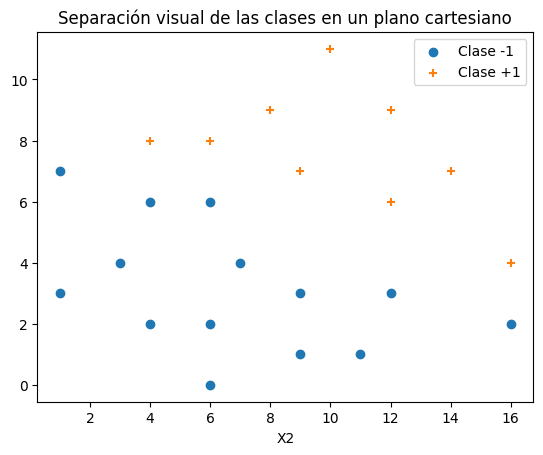

* Respuestas escritas a las preguntas guía en celdas Markdown.

### **Respuesta de la pregunta guía de la Actividad 1.a — Inspección inicial**

Cada fila de "X" representa una instancia individual del conjunto de datos en un plano bidimensional. Cada valor de "y" representa la etiqueta de la clase real asociada a la instancia ubicada en la misma posción de "X". Este problema se conoce como clasificación binaria porque el objetivo del modelo es asignar cada entrada a únicamente dos categorías o clases mutuamente excluyentes.

### **Respuesta de la pregunta guía de la Actividad 1.b — Separación visual de las clases**

Si, visualmente parece posible trazar al menos una recta que deje los puntos de la clase "-1" de un lado y los de la clase "+1" del otro, aunque con un margen estrecho en ciertas zonas. Sin embargo, como los dos grupos están relativamente cerca en algunos puntos, la inclinación y posición de la recta deberán ajustarse con cuidado durante el entrenamiento correspondiente.

# **Fase 2. Fundamento del Perceptrón**

El perceptrón es un clasificador lineal supervisado. Recibe entradas numéricas, calcula una suma ponderada, aplica una función de activación y produce una salida binaria.

Para una instancia con dos entradas:

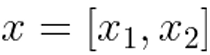


El perceptrón calcula:

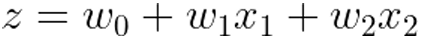


Donde:
* w0 es el bias o sesgo
* w1 es el peso asociado a x1
* w2 es el peso asociado a x2

La salida se obtiene aplicando la función escalón bipolar:

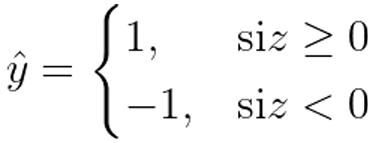


La frontera de decisión está definida por:

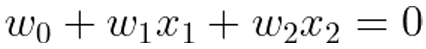

## **2.1 Actividades sobre el modelo**

### **Actividad 2.a — Vector de pesos**

Crea una función llamada initialize_weights() que retorne tres pesos aleatorios pequeños. Los pesos deben generarse en un rango pequeño, por ejemplo entre -0.5 y 0.5.

**Pregunta guía:** ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?

In [24]:
# Se importa el módulo estándar "random" de Python
import random


# Se define la función "initialize_weights()" sin parámetros para generar 3 pesos pequeños
def initialize_weights():
  # Se crea una lista vacía donde guardaremos los tres pasos aleatorios
  weights = []
  # Se agrega el bucle "for" para repetir el proceso 3 veces
  for i in range(3):
    # Se indenta dentro del ciclo para agregra un peso en el rango correspondiente en cada vuelta
    weights.append(random.uniform(-0.5, 0.5))
  # Retornamos la lista con los tres pesos iniciales
  return weights


# LLamamos a la función y guardamos el vector resultante en la variable "pesos"
pesos = initialize_weights()
# Mostramos en pantalla los pesos iniciales generados
print("Pesos iniciales: ", pesos)

Pesos iniciales:  [0.1199873996146662, 0.27471935618300014, 0.023956450949907726]


**RESPUESTA A LA PREGUNTA GUÍA:** El vector de peso tiene tres valores iniciales porque el primer valor "w0" corresponde al bias (sesgo), mientras que el "w1" y "w2" corresponden a los pesos asociados a "x1" y "x2" respectivamente. El bias cumple la función de desplazar la frontera de decisión respecto al origen del plano cartesiano, ya que sin el "w0" la recta estaría obligada a pasar siempre por (0,0), lo que limitaría enormemente su capacidad de separar clases que no estén centradas en el origen.

### **Actividad 2.b — Función de activación**

Crea una función llamada activation(z) que reciba el valor de la suma ponderada y retorne el resultado de la función escalón bipolar:

**Pregunta guía:** ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?

In [25]:
# Definimos la función "activation(z)" que recibe la suma ponderada "z"
def activation(z):
  # Evaluamos si la suma ponderada es mayor o igual que cero
  if z >= 0:
    # Si se cumple, retornamos la etiqueta de la clase positiva
    return 1
  # Si "z" es estrictamente menor que cero
  else:
    # Se retorna la etiqueta de la clase negativa
    return -1


# Se agregan llamadas de prueba para ver el resultado en la consola
print("Prueba con z = -2.5 --> Salida: ", activation(-2.5))
print("Prueba con z = 0.0 --> Salida: ", activation(0.0))
print("Prueba con z = 1.8 --> Salida: ", activation(1.8))

Prueba con z = -2.5 --> Salida:  -1
Prueba con z = 0.0 --> Salida:  1
Prueba con z = 1.8 --> Salida:  1


**RESPUESTA A LA PREGUNTA GUÍA:** Se utilizan las etiquetas "-1" y "1" porque es simétrica con respecto a cero y facilita la regla de actualización del perceptrón. Cuando hay error, el término "y - y_hat" toma valores no nulos más claros para ajustar los pesos en la dirección correcta.

### **Actividad 2.c — Cálculo de salida**

Crea una función llamada perceptron_compute(x, w). La función debe recibir una sola instancia x = [x1, x2] y el vector de pesos w = [w0, w1, w2]. Esta función debe calcular la suma ponderada z y retornar la salida producida por la función de activación.

**Pregunta guía:** ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?

In [27]:
# Definimos la función "perceptron_compute(x, w)"
def perceptron_compute(x, w):
  # Inicializamos la suma ponderada con el valor del bias (w[0])
  suma_ponderada = w[0]
  # Recorremos cada índice de la instancia de entrada
  for i in range(len(x)):
    # Multiplicamos cada entrada por su peso correspondiente y lo sumamos a "z"
    suma_ponderada += x[i] * w[i + 1]
  # Aplicamos la función de escalón bipolar
  if suma_ponderada >= 0:
    return 1
  else:
    return -1

# Prueba manual con tres instancias del dataset usando los pesos iniciales generados anteriormente
instancia_1 = matriz_X[0]
instancia_2 = matriz_X[7]
instancia_3 = matriz_X[14]

# Calculamos y mostramos la salida predicha para cada instancia de prueba
print("Instancia ", instancia_1, "--> Salida: ", perceptron_compute(instancia_1, pesos))
print("Instancia ", instancia_2, "--> Salida: ", perceptron_compute(instancia_2, pesos))
print("Instancia ", instancia_3, "--> Salida: ", perceptron_compute(instancia_3, pesos))

Instancia  [1, 7] --> Salida:  1
Instancia  [6, 0] --> Salida:  1
Instancia  [4, 8] --> Salida:  1


**RESPUESTA A LA PREGUNTA GUÍA:** La suma ponderada es un valor numérico continuo que resulta de combinar linealmente el bias y las entradas multiplicadas por sus respectivos pesos. Mientras que la salida del perceptrón es el valor discreto de clase obtenido tras pasar "z" por la función de activación. No basta con calcular solo "z" porque no entrega una decisión de clase binaria, en la que la función de activación es la que aplica el umbral en cero para asignar la instancia a una clase o a otra clase y así poder comparar la predicción contra la etiqueta real.

**Entregable de la Fase 2**

Al terminar, tu notebook debe contener:

* Función initialize_weights() implementada

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 2.a — Vector de pesos.

* Función activation(z) implementada

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 2.b — Función de activación.

* Función perceptron_compute(x, w) implementada

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 2.c — Cálculo de salida.

* Prueba manual con al menos tres instancias del dataset

In [28]:
# Se asegura de que "X" y "y" estén disponibles
X = matriz_X
y = vector_y
# Se genera un vector de 3 pesos aleatorios pequeños en [-0.5, 0.5]
pesos_prueba = initialize_weights()
# Se mujestran los pesos iniciales que se usarán en esta prueba manual
print("Pesos utilizados en la prueba manual [w0, w1, w2]: ", pesos_prueba)
print("-" * 50)
# Se selecciona al menos tres instancias del dataset a través de sus índices
indices_prueba = [0, 7, 14]
# Se recorren los índices seleccionados para evaluar cada instancia manualmente
for i in indices_prueba:
  # Obtenemos la instancia ubicada en la posición "i" de "X"
  instancia = X[i]
  # Obtenemos la etiqueta real correspondiente a esa misma instancia en "y"
  clase_real = y[i]
  # Se calcula la salida del perceptrón llamando a "perceptron_compute()"
  salida_predicha = perceptron_compute(instancia, pesos_prueba)
  # Imprimimos el detalle de la instancia, su clase real y la salida predicha por el modelo
  print(f"Instancia #{i} --> {instancia} | Clase real (y): {clase_real} | Salida predicha: {salida_predicha}")

Pesos utilizados en la prueba manual [w0, w1, w2]:  [-0.40793630613713716, 0.1910948466725494, 0.40780275307181946]
--------------------------------------------------
Instancia #0 --> [1, 7] | Clase real (y): -1 | Salida predicha: 1
Instancia #7 --> [6, 0] | Clase real (y): -1 | Salida predicha: 1
Instancia #14 --> [4, 8] | Clase real (y): 1 | Salida predicha: 1


* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 2.a — Vector de pesos.**

El vector de peso tiene tres valores iniciales porque el primer valor "w0" corresponde al bias (sesgo), mientras que el "w1" y "w2" corresponden a los pesos asociados a "x1" y "x2" respectivamente. El bias cumple la función de desplazar la frontera de decisión respecto al origen del plano cartesiano, ya que sin el "w0" la recta estaría obligada a pasar siempre por (0,0), lo que limitaría enormemente su capacidad de separar clases que no estén centradas en el origen.

### **Respuesta de la pregunta guía de la Actividad 2.b — Función de activación.**

Se utilizan las etiquetas "-1" y "1" porque es simétrica con respecto a cero y facilita la regla de actualización del perceptrón. Cuando hay error, el término "y - y_hat" toma valores no nulos más claros para ajustar los pesos en la dirección correcta.

### **Respuesta de la pregunta guía de la Actividad 2.c — Cálculo de salida.**

La suma ponderada es un valor numérico continuo que resulta de combinar linealmente el bias y las entradas multiplicadas por sus respectivos pesos. Mientras que la salida del perceptrón es el valor discreto de clase obtenido tras pasar "z" por la función de activación. No basta con calcular solo "z" porque no entrega una decisión de clase binaria, en la que la función de activación es la que aplica el umbral en cero para asignar la instancia a una clase o a otra clase y así poder comparar la predicción contra la etiqueta real.

# **Fase 3. Visualización de la Frontera de Decisión**

El perceptrón divide el plano mediante una recta. Para visualizar esa recta, partimos de la ecuación:

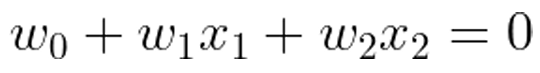

Si despejamos x2:

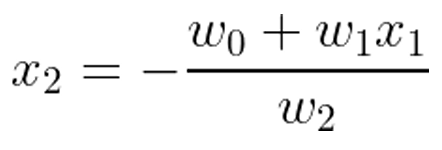

Esta expresión permite graficar la frontera de decisión.

## **3.1 Actividades de visualización**

### **Actividad 3.a — Función de graficación**

Crea una función llamada perceptron_plot(X, y, w, title). La función debe:

* Graficar los puntos de la clase -1.
* Graficar los puntos de la clase 1.
* Graficar la frontera de decisión correspondiente al vector de pesos w.
* Colocar título, etiquetas de ejes, leyenda y cuadrícula.

Considera el siguiente caso especial:

* Si w2 ≠ 0, puedes despejar x2
* Si w2 = 0, la recta no puede despejarse de esa forma y debes evitar la división para cero.

**Pregunta guía:** ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si
los pesos iniciales son aleatorios?

In [29]:
# Se importa matplotlib.pyplot para que se pueda graficar los puntos y la frontera de decisión
import matplotlib.pyplot as plt


# Se define la función "perceptron_plot(X, y, w, title)" solicitado en la actividad correspondiente
def perceptron_plot(X, y, w, title):
  # Se crea listas vacías para guardar las coordenadas de la clase "-1"
  x1_neg = []
  x2_neg = []
  # Se crea listas vacías para guardar las coordenadas de la clase "+1"
  x1_pos = []
  x2_pos = []
  # Se crea una lista con todos los valores de "x1" para determinar el rango horizontal del plano
  todos_los_x1 = []

  # Se recorre cada instancia de "X" junto con su etiqueta de "y"
  for i in range(len(X)):
    x_1 = X[i][0]
    x_2 = X[i][1]
    etiqueta = y[i]
    todos_los_x1.append(x_1)
    # Se clasifican las coordenadas según la etiqueta real
    if etiqueta == -1:
      x1_neg.append(x_1)
      x2_neg.append(x_2)
    elif etiqueta == 1:
      x1_pos.append(x_1)
      x2_pos.append(x_2)
  # Se crea una nueva figura para la gráfica
  plt.figure()
  # Se grafica los puntos de la clase -1
  plt.scatter(x1_neg, x2_neg, marker = 'o', label = 'Clase -1')
  # Se grafica los puntos de la clase +1
  plt.scatter(x1_pos, x2_pos, marker = '+', label = 'Clase +1')
  # Se extrae los componentes del vector de pesos
  # Bias o sesgo
  w0 = w[0]
  # Peso asociado a x1
  w1 = w[1]
  # Peso asociado a x2
  w2 = w[2]
  # Se definen los extremos en x1 con un pequeño margen de 1 unidad a cada lado
  x1_min = min(todos_los_x1) - 1
  x1_max = max(todos_los_x1) + 1
  # Caso 1: Si w2 es distinto de cero, podemos despejar x2 en función de x1
  if w2 != 0:
    # Se calcula x2 para el extremo izquierdo de x1
    x2_min = -(w0 + w1 * x1_min) / w2
    # Se calcula x2 para el extremo derecho de x1
    x2_max = -(w0 + w1 * x1_max) / w2
    # Se dibuja la recta que une a ambos puntos extremos. Es la frontera de decisión
    plt.plot([x1_min, x1_max], [x2_min, x2_max])
  # Caso 2: si w2 es igual a cero, evitamos división por cero
  else:
    # Si w1 tampoco es cero, la ecuación w0 + (w1 + x1) = 0 define una recta vertical
    if w1 != 0:
      x1_vertical = -w0 / w1
      # Se grafica la frontera de decisión para w2 = 0
      plt.axvline(x = x1_vertical)
    # Si tanto w1 como w2 son cero, no existe una recta definida en el plano
    else:
      print("No se puede trazar una frontera de decisión")

  # Se coloca el título recibido como parámetro
  plt.title(title)
  # Se coloca las etiquetas de los ejes correspondientes
  plt.xlabel("X1")
  plt.ylabel("X2")
  # Se activa la leyenda para identificar las clases y la frontera
  plt.legend()
  # Se muestra la gráfica
  plt.show()

**RESPUESTA A LA PREGUNTA GUÍA:** Geométricamente, la recta definida representa la frontera de decisión lineal que divide el plano bidimensional en dos semiplanos. Cuando los pesos iniciales son aleatorios, la recta toma una posición y una inclinación al azar dentro del plano sin tener relación previa con la distribución real de las clases "-1" y "+1".

### **Actividad 3.b — Gráfica con pesos iniciales**

Inicializa pesos aleatorios pequeños y grafica la frontera inicial.

Pesos iniciales (w_initial):  [-0.14026499266176773, -0.1905800041733734, 0.22734308119200397]


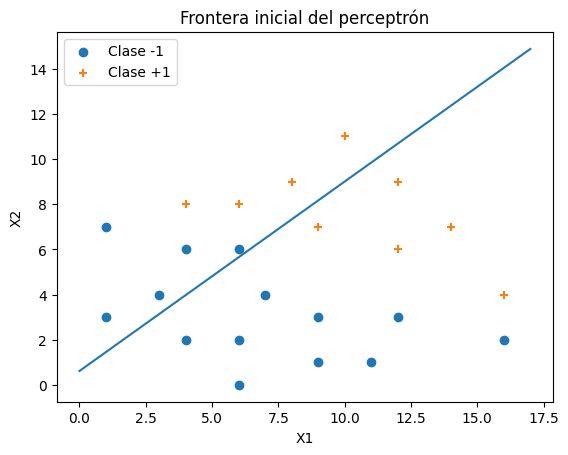

In [41]:
# Se inicializa tres pesos aleatorios pequeños en [-0.5, 0.5] para la frontera inicial
w_initial = initialize_weights()
# Se muestra los pesos iniciales para referencia
print("Pesos iniciales (w_initial): ", w_initial)
# Graficamos los datos junto con la frontera de decisión inicial del perceptrón
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

**Pregunta guía:** ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?

**RESPUESTA A LA PREGUNTA GUÍA:** La frontera inicial no clasifica correctamente todos los puntos, porque sus pesos se generaron de forma aleatoria sin haber visto las etiquetas reales "y". No se debería esperar que una frontera con pesos aleatorios sea correcta porque el modelo aún no ha pasado por el proceso de aprendizaje supervisado.

**Entregable de la Fase 3**
Al terminar, tu notebook debe contener:

* Función perceptron_plot(X, y, w, title) implementada

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 3.a — Función de graficación.

* Gráfica de los datos con la frontera inicial

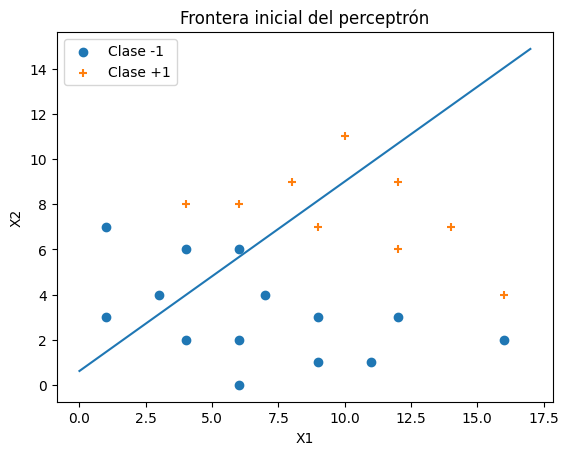

* Explicación escrita de la frontera de decisión

En un perceptrón bidimensional la suma ponderada es "z = w0 + w1x1 + w2x2", en la que la frontera de decisión corresponde al conjunto de puntos del plano donde "z = 0". Esta recta actúa como un límite entre las dos regiones de decisión del modelo: a un lado de la recta se cumple que "z >= 0" y al otro lado "z < 0". En el caso especial donde "w_2 = 0", no se puede despejar "x_2" de esta forma y se debe evitar la división por cero. En la frontera inicial, como los pesos son aleatorios pequeños en [-0.5, 0.5], la recta aparece en una posición y pendiente arbitrarias y aún no separa correctamente ambas clases.

* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 3.a — Función de graficación**

Geométricamente, la recta definida representa la frontera de decisión lineal que divide el plano bidimensional en dos semiplanos. Cuando los pesos iniciales son aleatorios, la recta toma una posición y una inclinación al azar dentro del plano sin tener relación previa con la distribución real de las clases "-1" y "+1".

### **Respuesta de la pregunta guía de la Actividad 3.b — Gráfica con pesos iniciales**

La frontera inicial no clasifica correctamente todos los puntos, porque sus pesos se generaron de forma aleatoria sin haber visto las etiquetas reales "y". No se debería esperar que una frontera con pesos aleatorios sea correcta porque el modelo aún no ha pasado por el proceso de aprendizaje supervisado.

# **Fase 4. Entrenamiento del Perceptrón**

El perceptrón aprende modificando sus pesos cuando comete errores. Para cada instancia de entrenamiento, se calcula una predicción. Si la predicción es incorrecta, los pesos se actualizan.

La regla de actualización es:

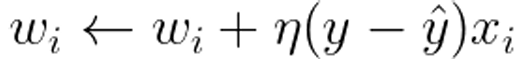

Para el bias:

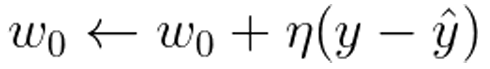

Donde:
* η es la tasa de aprendizaje
* y es la etiqueta real
* ŷ es la etiqueta predicha
* xi es la entrada correspondiente

## **4.1 Actividades de entrenamiento**

### **Actividad 4.a — Implementación de la función de aprendizaje**

Crea una función llamada perceptron_learning(X, y, w, lr, max_epochs). La función debe recibir:

* Matriz de datos X
* Vector de etiquetas y
* Pesos iniciales w
* tasa de aprendizaje lr
* Número máximo de épocas max_epochs.

La función debe retornar:

* Pesos finales
* Número de épocas realizadas
* Número total de actualizaciones
* Lista con la evolución de pesos W_values;
* Lista con la evolución del error E_values.

La función debe entrenar hasta que:

* No exista ningún error de clasificación en una época o
* Se alcance el número máximo de épocas.

**Pregunta guía:** ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?

In [42]:
# Se define la función principal de entrenamiento del perceptrón
def perceptron_learning(X, y, w, lr, max_epochs):
  # Se crea una copia de los pesos iniciales
  pesos = list(w)
  # Se inicializa el contador acumulado de actualizaciones de pesos
  total_actualizaciones = 0
  # Se inicializa el contador de épocas efectivamente ejecutadas
  epocas_realizadas = 0
  # Inicializamos la lista que almacenará la copia de los pesos
  W_values = []
  # Inicializamos la lista que almacenará la tasa de error por cada época
  E_values = []

  # Se itera por épocas hasta un máximo de "max_epochs"
  for epoca in range(max_epochs):
    # Se registra que se está realizando una época más
    epocas_realizadas += 1
    # Se reinicia el contador de errores de clasificación para la época actual
    errores = 0

    # Se recorre cada instancia del dataset "X" junto con su etiqueta real en "y"
    for i in range(len(X)):
      # Se extrae la instancia actual
      instancia = X[i]
      # Se extrae la etiqueta real correspondiente a esa instancia
      y_real = y[i]
      # Se calcula la predicción actual del perceptrón usando la función definida en la Fase 2
      y_pred = perceptron_compute(instancia, pesos)

      # Se verifica si hubo error de clasificación
      if y_pred != y_real:
        # Se incrememnta el número de errores de la época actual
        errores += 1
        # Se incrementa el total acumulado de actualizaciones realizadas
        total_actualizaciones += 1
        # Se calcula el término de error para no repetirlo
        diferencia_error = y_real - y_pred
        # Se actualiza el bias
        pesos[0] = pesos[0] + lr * diferencia_error
        # Se actualiza cada peso asociado a cada entrada
        for j in range(len(instancia)):
          pesos[j + 1] = pesos[j + 1] + lr * diferencia_error * instancia[j]

    # Se calcula la tasa del error de la época
    tasa_error = errores / len(X)
    # Se guarda la tasa del error de esta época
    E_values.append(tasa_error)
    # Se guarda una copia nueva de la lista de pesos
    W_values.append(list(pesos))
    # Si no hubo ningún error en esa época, el modelo separa todas las instancias
    if errores == 0:
      break
  return pesos, epocas_realizadas, total_actualizaciones, W_values, E_values

# Se genera pesos iniciales pequeños para probar el perceptron_learning() en consola
w_prueba_4_a = initialize_weights()
# Se ejecuta la función de aprendizaje
pesos_fin_a_4, epocas_a_4, act_a_4, W_historial_a_4, E_historial_a_4 = perceptron_learning(X, y, w_prueba_4_a, lr = 0.5, max_epochs = 1000)
# Se imprime los resultados retornados para verificar en consola
print("Pesos iniciales: ", w_prueba_4_a)
print("Pesos finales: ", pesos_fin_a_4)
print("Epocas realizadas: ", epocas_a_4)
print("Total de actualizaciones: ", act_a_4)
print("Cantidad de registros en W_values: ", len(W_historial_a_4))
print("Cantidad de registros en E_values: ", len(E_historial_a_4))

Pesos iniciales:  [-0.4560603189368412, -0.42728277334097975, 0.30522733987428063]
Pesos finales:  [-52.45606031893684, 2.5727172266590195, 5.305227339874278]
Epocas realizadas:  100
Total de actualizaciones:  288
Cantidad de registros en W_values:  100
Cantidad de registros en E_values:  100


**RESPUESTA A LA PREGUNTA GUÍA:** Es necesario incluir un número máximo de épocas porque evita que el ciclo de entrenamiento se ejecute indefinidamente si la condición de "0" errores nunca se cumple. Si el dataset no fuera linealmente separable, ninguna recta podría separar perfectamente ambas clases, por lo que siempre existirá al menos un error en cada época. Sin el "max_epochs", el perceptrón seguirá actualizando pero sin converger a cero errores.

### **Actividad 4.b — Registro del error**

Durante cada época, calcula la tasa de error:

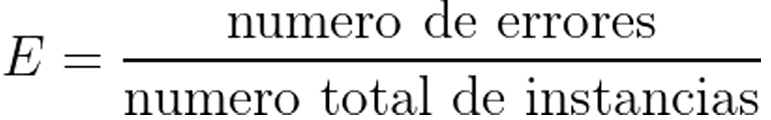

Guarda ese valor en la lista E_values.

**Pregunta guía:** ¿Qué significa que la tasa de error llegue a cero?

In [43]:
# Lista donde se acumula la tasa de error por cada época dentro del perceptron_learning
E_values = []
# Se simula el cálculo de la tasa de error en una determinada época
errores_ejemplo = 3
tasa_error_ejemplo = errores_ejemplo / len(X)
# Se guarda la tasa de error de ejemplo en E_values
E_values.append(tasa_error_ejemplo)
# Se muestra el registro de ejemplo y el historial de la pruevba 4.a
print("Tasa de error de ejemplo: ", E_values)
print("Evolución del error en la prueba 4.a: ", E_historial_a_4)

Tasa de error de ejemplo:  [0.13043478260869565]
Evolución del error en la prueba 4.a:  [0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.130434

**RESPUESTA A LA PREGUNTA GUÍA:** Significa que el perceptrón clasificó correctamente el 100% de las instancias del conjunto de entrenamiento.

### **Actividad 4.c — Registro de pesos**

Después de cada época, guarda una copia del vector de pesos en W_values. **Importante:** no guardes la misma referencia del objeto w; guarda una copia de sus valores.

**Pregunta guía:** ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?

In [44]:
# Lista donde se guarda el historial de vectores de pesos al término de cada época
W_values = []
# Se toma un vector de ejemplo y se guarda una copia para no compartir referencia
pesos_ejemplo = [0.1, -0.2, 0.3]
W_values.append(list(pesos_ejemplo))
# Se realiza una demostración de que W_values no se altera
pesos_ejemplo[0] = 99.0
W_values.append(list(pesos_ejemplo))
# Se muestra en consola la prueba de copia y los primeros/últimos pesos guardados en 4.a
print("W_values con copias independientes: ", W_values)
print("Primer vector de pesos guardado en prueba 4.a: ", W_historial_a_4[0])
print("último vector de pesos guardado en prueba 4.a: ", W_historial_a_4[-1])

W_values con copias independientes:  [[0.1, -0.2, 0.3], [99.0, -0.2, 0.3]]
Primer vector de pesos guardado en prueba 4.a:  [-0.4560603189368413, 2.5727172266590204, 1.3052273398742802]
último vector de pesos guardado en prueba 4.a:  [-52.45606031893684, 2.5727172266590195, 5.305227339874278]


**RESPUESTA A LA PREGUNTA GUÍA:** Porque la lista de pesos se modifica en su lugar durante el entrenamiento. El problema que aparecería sería que todos los elementos de "W_values" apuntaría al mismo objeto en memoria y al final contendrían únicamente los pesos finales repetidos.

**Entregable de la Fase 4**

Al terminar, tu notebook debe contener:

* Función perceptron_learning(X, y, w, lr, max_epochs) implementada

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 4.a — Implementación de la función de aprendizaje.

* Registro de errores por época

**Primeras épocas:** 0.08695652173913043

**Resultado obtenido durante el entrenamiento:** El error varía entre distintas épocas.

**Última época:** 0.0

* Registro de pesos por época

**Pesos iniciales:** [-0.4560603189368412, -0.42728277334097975, 0.30522733987428063]

**Primer vector guardado en "W_values":** [-0.4560603189368413, 2.5727172266590204, 1.3052273398742802]

**último vector guardado en "W_values":** [-52.45606031893684, 2.5727172266590195, 5.305227339874278]

* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 4.a — Implementación de la función de aprendizaje**

Es necesario incluir un número máximo de épocas porque evita que el ciclo de entrenamiento se ejecute indefinidamente si la condición de "0" errores nunca se cumple. Si el dataset no fuera linealmente separable, ninguna recta podría separar perfectamente ambas clases, por lo que siempre existirá al menos un error en cada época. Sin el "max_epochs", el perceptrón seguirá actualizando pero sin converger a cero errores.

### **Respuesta de la pregunta guía de la Actividad 4.b — Registro del error**

Significa que el perceptrón clasificó correctamente el 100% de las instancias del conjunto de entrenamiento.

### **Respuesta de la pregunta guía de la Actividad 4.c — Registro de pesos**

Porque la lista de pesos se modifica en su lugar durante el entrenamiento. El problema que aparecería sería que todos los elementos de "W_values" apuntaría al mismo objeto en memoria y al final contendrían únicamente los pesos finales repetidos.

# **Fase 5. Entrenamiento con tasa de aprendizaje 0.5**

En esta fase entrenarás el perceptrón con:
* lr = 0.5
* max_epochs = 1000

## **5.1 Actividades de entrenamiento inicial**

### **Actividad 5.a — Entrena el modelo**

Inicializa pesos aleatorios y entrena el perceptrón.

Muestra:
* Pesos iniciales
* Pesos finales
* Número de épocas
* Número total de actualizaciones
* Error final

**Pregunta guía:** ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista y la gráfica final?

In [45]:
# Se genera los pesos iniciales aleatorios en el rango de [-0.5, 0.5]
w = initialize_weights()
# Se entrena el perceptrón con una taza de aprendizaje de lr = 0.5 y un máximo de 1000 épocas, para que la función retorne los datos correspondientes
final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X,
    y,
    w,
    lr=0.5,
    max_epochs=1000
)
# Se imprime en consola los pesos iniciales generadosa antes del entrenamiento
print("Pesos iniciales: ", w)
# Se imprime los pesos finales ajustados tras finalizar el entrenamiento
print("Pesos finales: ", final_w)
# Se imprime la cantidad de épocas que necesitó el algoritmo para detenerse
print("Número de épocas: ", epochs)
# Se imprime cuantas veces se actualizaron los pesos durante todo el entrenamiento
print("Número total de actualizaciones: ", updates)
# Se imprime el último elemento que corresponde a la tasa de error de la última época
print("Error final: ", E_values[-1])

Pesos iniciales:  [-0.13709931286500854, 0.451081812535461, 0.13480989792389098]
Pesos finales:  [-182.13709931286502, 8.451081812535463, 20.134809897923887]
Número de épocas:  385
Número total de actualizaciones:  1272
Error final:  0.0


**RESPUESTA A LA PREGUNTA GUÍA:** Si, el perceptrón si pudo converger antes de alcanzar el límite de 1000 épocas.

Esto se puede comprobar de dos maneras:

**1.** Con la lista "E_values", en la que el número de épocas realizadas es menor a "max_epochs" y el último valor registrado en "E_values" es igual a 0.0, lo que confirma que el modelo alcanzó cero errores en clasificación de una época completa.

**2.** Con la gráfica fina, cuando se traza la recta definida por "final_w", se observa visualmente que todos los puntos de la clase "-1" quedan de un lado de la frontera de decisión y todos los puntos de la clase "+1" quedan del otro lado, sin ningún punto mal clasificado.

### **Actividad 5.b — Frontera final**

Grafica la frontera de decisión final. perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")

**Pregunta guía:** ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?

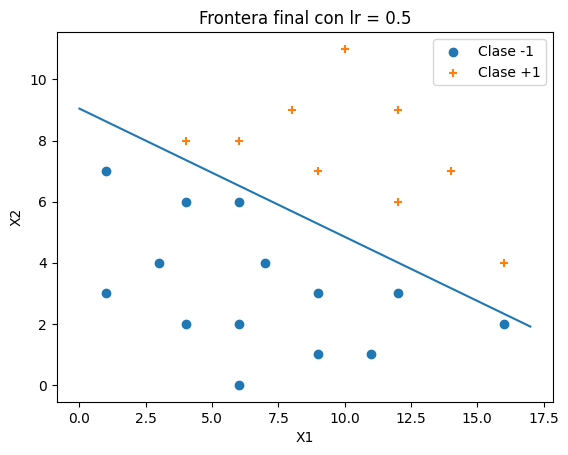

In [46]:
# Se llama a perceptron_plot() pasando la matriz "X", etiquetas "y", pesos finales "final_w" y el título solicitado
perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")

**RESPUESTA A LA PREGUNTA GUÍA:** Si, la frontera inicial se separa correctamente las dos clases correspondientes.

La diferencia que existe es que en la frontera inicial, la recta tenía una posición y pendiente arbitrarias producto de los pesos aleatorios. Mientras que en la frontera final, la recta se desplazó y rotó hasta ubicarse exactamente en la franja que separa ambas clases sin cometer errores.

**Entregable de la Fase 5**

Al terminar, tu notebook debe contener:

* Entrenamiento completo con lr = 0.5

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 5.a — Entrena el modelo. El entrenamiento se realizó con lr = 0.5 y max_epochs = 1000 hasta lograr 0 errores.

* Pesos iniciales y finales

**Pesos iniciales:** [-0.13709931286500854, 0.451081812535461, 0.13480989792389098]

**Pesos finales:** [-182.13709931286502, 8.451081812535463, 20.134809897923887]

* Número de épocas

**Número de épocas:** 385

* Número de actualizaciones

**Número total de actualizaciones:** 1272

* Gráfica de la frontera final

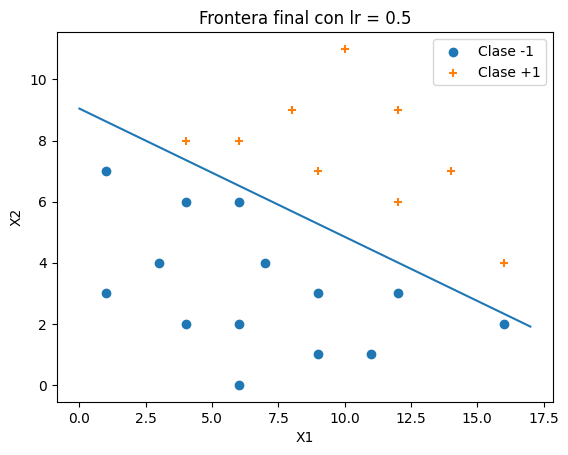

* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 5.a — Entrena el modelo**
Si, el perceptrón si pudo converger antes de alcanzar el límite de 1000 épocas.

Esto se puede comprobar de dos maneras:

**1.** Con la lista "E_values", en la que el número de épocas realizadas es menor a "max_epochs" y el último valor registrado en "E_values" es igual a 0.0, lo que confirma que el modelo alcanzó cero errores en clasificación de una época completa.

**2.** Con la gráfica fina, cuando se traza la recta definida por "final_w", se observa visualmente que todos los puntos de la clase "-1" quedan de un lado de la frontera de decisión y todos los puntos de la clase "+1" quedan del otro lado, sin ningún punto mal clasificado.

### **Respuesta de la pregunta guía de la Actividad 5.b — Frontera final**
Si, la frontera inicial se separa correctamente las dos clases correspondientes.

La diferencia que existe es que en la frontera inicial, la recta tenía una posición y pendiente arbitrarias producto de los pesos aleatorios. Mientras que en la frontera final, la recta se desplazó y rotó hasta ubicarse exactamente en la franja que separa ambas clases sin cometer errores.

# **Fase 6. Predicción con Nuevas Instancias**

Una vez entrenado el perceptrón, se utilizará para clasificar nuevas instancias que no fueron usadas durante el entrenamiento. Usa las siguientes instancias:

X_test = [
    [5, 5],
    [10, 6],
    [6, 10]
]

## **6.1 Actividades de predicción**

### **Actividad 6.a — Clasificación de nuevas instancias**

Usa perceptron_compute(X_test, final_w) para obtener la salida de cada instancia. Construye una tabla con el siguiente formato:

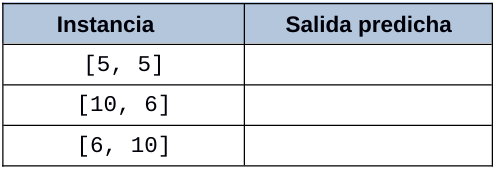

**Pregunta guía:** ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?

In [47]:
# Definimos las nuevas instancias de prueba que no fueron vistas durante el entrenamiento
X_test = [[5, 5], [10, 6], [6, 10]]
# Se crea una lista para almacenar las predicciones
predicciones = []
# Se recorre cada nueva instancia contenida en X_test
for instancia in X_test:
  # Se llama a la función "perceptron_compute()"
  pred = perceptron_compute(instancia, final_w)
  # Se guarda la predicción obtenida para esta instancia
  predicciones.append(pred)
# Se muestra en consola la lista general de salidas predichas
print("Salida del perceptrón: ", predicciones)
# Se muestra en consola la lista general de salidas predichas
print("\nInstancia   |   Salida predicha")
print("-" * 28)
for i in range(len(X_test)):
  # Se imprime cada instancia con su respectiva salida predicha alineadas en columnas
  print(f"{str(X_test[i]):<10}  |   {predicciones[i]}")

Salida del perceptrón:  [-1, 1, 1]

Instancia   |   Salida predicha
----------------------------
[5, 5]      |   -1
[10, 6]     |   1
[6, 10]     |   1


**RESPUESTA A LA PREGUNTA GUÍA:** Si, las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión aprendida.

### **Actividad 6.b — Dataset extendido**

Agrega las nuevas instancias a una copia del dataset original. Agrega también sus salidas predichas al vector de etiquetas.

Luego grafica nuevamente el dataset extendido con la frontera aprendida.

**Pregunta guía:** ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta.

Total de instancias en el dataset extendido:  26
Total de etiquetas en y_extendido:  26


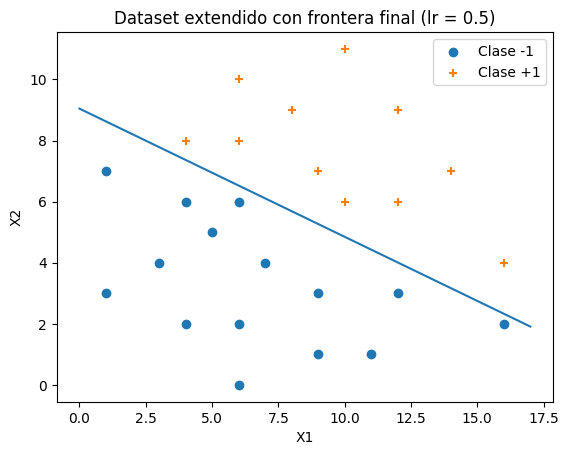

In [48]:
# Se crea una copia independiente de la matriz "X" para no modificar el dataset original
X_extendido = [list(fila) for fila in X]
# Se crea una copia independiente del vector "y" para no modificar las etiquetas originales
y_extendido = list(y)
# Se agrega las nuevas instancias de "X_test" y sus predicciones a las copias extendidas
for i in range(len(X_test)):
  # Se añade una copia de la instancia [x1, x2] a X_extendido
  X_extendido.append(list(X_test[i]))
  # Se añade la predicción correspondiente a y_extendido
  y_extendido.append(predicciones[i])

# Se muestra en consola el nuevo tamaño del dataset extendido
print("Total de instancias en el dataset extendido: ", len(X_extendido))
print("Total de etiquetas en y_extendido: ", len(y_extendido))

# Se pasa X_extendido, y_extendido, final_w y el cuarto argumento obligatorio
perceptron_plot(X_extendido, y_extendido, final_w, "Dataset extendido con frontera final (lr = 0.5)")

**RESPUESTA A LA PREGUNTA GUÍA:** Cada nueva instancia queda asignada al semiplano que le corresponde según la recta definida por "final_w" y la regla del signo de "z".

Las predicciones más sensibles suelen ser aquellas que caen cerca de la frontera de decisión, debido a que el perceptrón solo aprende una frontera lineal a partir de los datos de entrenamiento, puntos cercanos al límite o en zonas donde las clases tienen menor margen de separación, por lo que su clasificación depende directamente de la recta específica que el algoritmo encontró durante el entrenamiento.

**Entregable de la Fase 6**

Al terminar, tu notebook debe contener:

* Tabla con las predicciones de las tres nuevas instancias

In [ ]:
Salida del perceptrón:  [-1, 1, 1]

Instancia   |   Salida predicha
----------------------------
[5, 5]      |   -1
[10, 6]     |   1
[6, 10]     |   1

* Dataset extendido

**Total de instancias en el dataset extendido:** 26

**Total de etiquetas en y_extendido:** 26 (23 originales más las 3 nuevas que se añadieron)

* Gráfica del dataset extendido

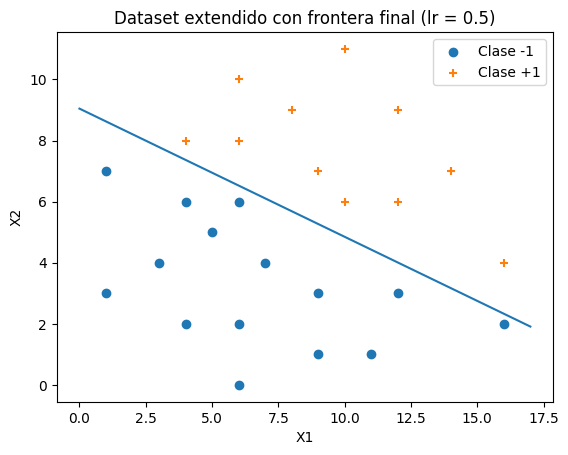

* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 6.a — Clasificación de nuevas instancias**

Si, las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión aprendida.

### **Respuesta de la pregunta guía de la Actividad 6.b — Dataset extendido**

Cada nueva instancia queda asignada al semiplano que le corresponde según la recta definida por "final_w" y la regla del signo de "z".

Las predicciones más sensibles suelen ser aquellas que caen cerca de la frontera de decisión, debido a que el perceptrón solo aprende una frontera lineal a partir de los datos de entrenamiento, puntos cercanos al límite o en zonas donde las clases tienen menor margen de separación, por lo que su clasificación depende directamente de la recta específica que el algoritmo encontró durante el entrenamiento.


# **Fase 7. Evolución de la Frontera de Decisión**

El entrenamiento del perceptrón modifica gradualmente los pesos. Como los pesos determinan la frontera de decisión, es posible observar cómo cambia la recta durante el aprendizaje.

## **7.1 Actividades de visualización del entrenamiento**

### **Actividad 7.a — Seis estados del entrenamiento**

Crea seis gráficas diferentes que muestren la evolución de la frontera de decisión. Selecciona los siguientes momentos:
* Estado inicial
* 20% del entrenamiento
* 40% del entrenamiento
* 60% del entrenamiento
* 80% del entrenamiento
* Estado final

Si el entrenamiento tuvo menos de seis épocas, grafica todos los estados disponibles.

**Pregunta guía:** ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?

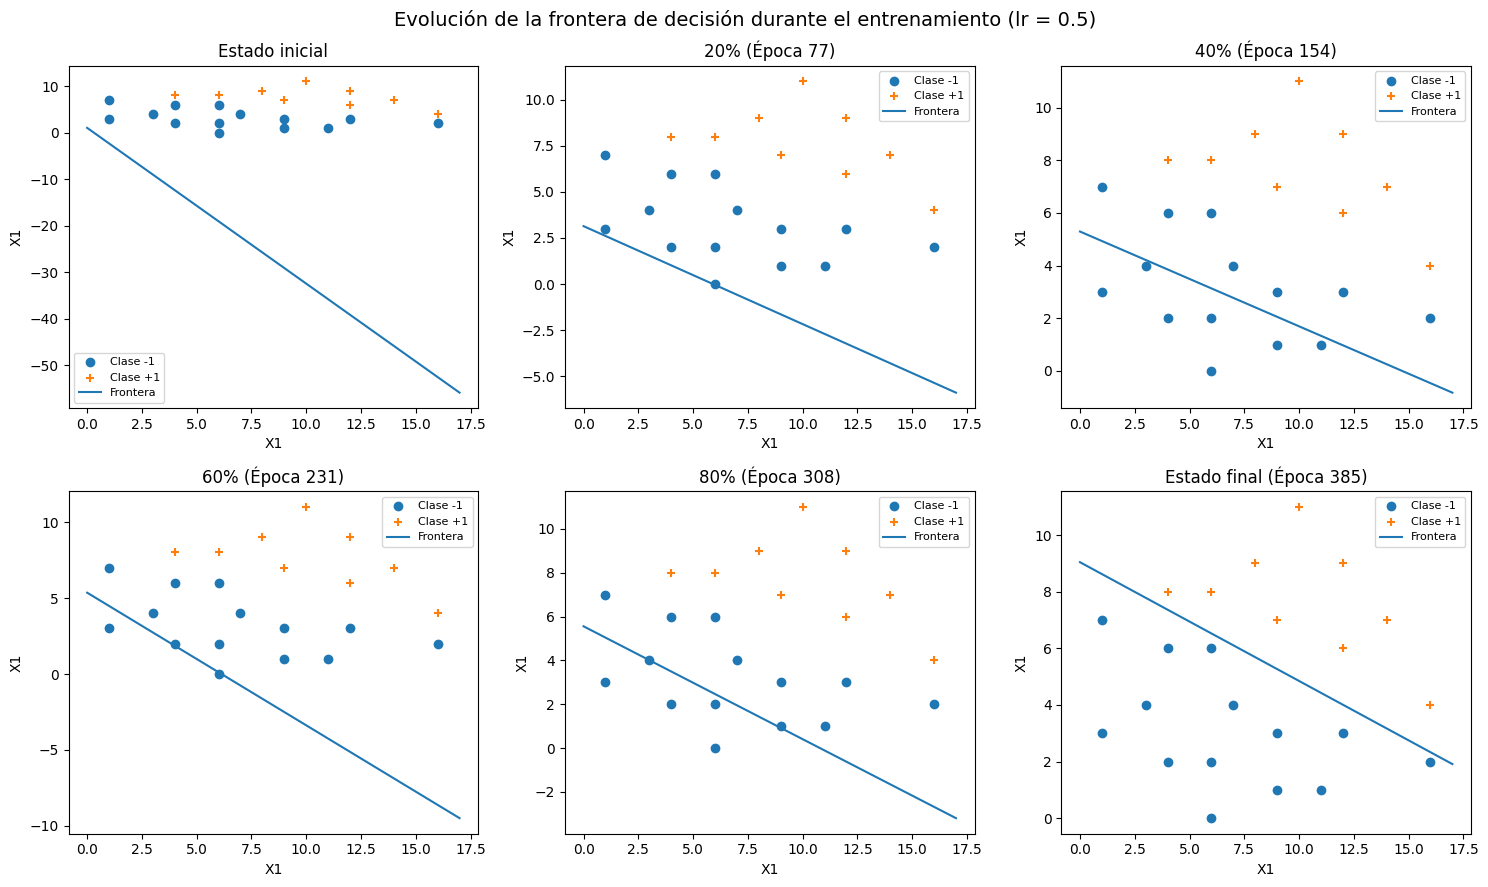

In [49]:
from matplotlib.collections import transforms
from matplotlib import axes
# Se importa matplotlib.pyplot para graficar los 6 estados de la frontera de decisión
import matplotlib.pyplot as plt
# Se separa las coordenadas de X1 y X2 según la clase real (-1 o +1) del dataset
x1_neg = []
x2_neg = []
x1_pos = []
x2_pos = []
todos_x1 = []
# Se recorre todas las instancias de "X" y sus etiquetas en "y"
for i in range(len(X)):
  x1_val = X[i][0]
  x2_val = X[i][1]
  etiqueta = y[i]
  todos_x1.append(x1_val)
  # Se clasifica los puntos según su etiqueta real
  if etiqueta == -1:
    x1_neg.append(x1_val)
    x2_neg.append(x2_val)
  elif etiqueta == 1:
    x1_pos.append(x1_val)
    x2_pos.append(x2_val)
# Se calcula el rango horizontal con un margen de 1 unidad a cada lado
x1_min = min(todos_x1) - 1
x1_max = max(todos_x1) + 1
# Se obtiene la cantidad total de épocas guardadas en W_values
total_epocas_hist = len(W_values)
# Si se tiene menos de 6 épocas, se toma todos los estados disponibles
if total_epocas_hist < 6:
  estados = [("Inicial", list(w))]
  for i in range(total_epocas_hist):
    estados.append((f"Época {i + 1}", W_values[i]))
else:
  # Se calcula los índices aproximados para 20%, 40%, 60% y 80% del entrenamiento
  i_20 = max(0, min(total_epocas_hist - 1, int(0.2 * total_epocas_hist) - 1))
  i_40 = max(0, min(total_epocas_hist - 1, int(0.4 * total_epocas_hist) - 1))
  i_60 = max(0, min(total_epocas_hist - 1, int(0.6 * total_epocas_hist) - 1))
  i_80 = max(0, min(total_epocas_hist - 1, int(0.8 * total_epocas_hist) - 1))
  # Se reune exactamente los 6 estados solicitados
  estados = [
      ("Estado inicial", list(w)),
      (f"20% (Época {i_20 + 1})", W_values[i_20]),
      (f"40% (Época {i_40 + 1})", W_values[i_40]),
      (f"60% (Época {i_60 + 1})", W_values[i_60]),
      (f"80% (Época {i_80 + 1})", W_values[i_80]),
      (f"Estado final (Época {total_epocas_hist})", W_values[-1]),
  ]

# Se crea una figura con cuadrícula de 2 filas y 3 columnas
fig, axes = plt.subplots(2, 3, figsize = (15,9))
# Se recorre cada uno de los estados seleccionados para graficarlo en su subgráfico
for k in range(len(estados)):
  # Se calcula la fila (0 o 1) y columna (0, 1 o 2) dentro de la cuadrícula 2x3
  fila = k // 3
  col = k % 3
  # Se selecciona el eje correspondiente al subgráfico actual
  ax = axes[fila, col]
  # Se extrae el nombre del estado y su vector de pesos [w0, w1, w2]
  nombre_estado, w_estado = estados[k]
  w0 = w_estado[0]
  w1 = w_estado[1]
  w2 = w_estado[2]
  # Se grafica los puntos de la clase -1 y de la clase +1 en el subgráfico actual
  ax.scatter(x1_neg, x2_neg, marker = 'o', label = "Clase -1")
  ax.scatter(x1_pos, x2_pos, marker = '+', label = "Clase +1")
  # Se traza la frontera de decisión según el valor de w2 para evitar división por cero
  if w2 != 0:
    x2_min = -(w0 + w1 * x1_min) / w2
    x2_max = -(w0 + w1 * x1_max) / w2
    ax.plot([x1_min, x1_max], [x2_min, x2_max], label = "Frontera")
  else:
    if w1 != 0:
      x1_vertical = -w0 / w1
      ax.axvline(x = x1_vertical, label = "Frontera (w2 = 0)")
    else:
      ax.text(0.5, 0.5, "Sin frontera definida", ha = "center", va = "center", transforms = ax.transAxes)
  # Se configura título, etiquetas de ejes y leyenda en cada subgráfico
  ax.set_title(nombre_estado)
  ax.set_xlabel("X1")
  ax.set_ylabel("X1")
  ax.legend(loc = "best", fontsize = 8)
  # Si hubo menos de 6 estados disponibles, ocultamos los subgráficos sobrantes
  for k in range(len(estados), 6):
    fila = k // 3
    col = k % 3
    axes[fila, col].axis("off")

# Se agrega un título general para toda la figura
plt.suptitle("Evolución de la frontera de decisión durante el entrenamiento (lr = 0.5)", fontsize = 14)
# Se ajusta los espacios entre subgráficos para que no se superpongan textos ni etiquetas
plt.tight_layout()
# Se muestra la figura completa en pantalla
plt.show()

**RESPUESTA A LA PREGUNTA GUÍA:** A medida que se actualizan los pesos en cada época donde ocurre un error, la frontera de decisión cambia de posición e inclinación hasta encontrar una recta que separe ambas clases sin errores. Mientras se realizaba el entrenamiento, se presentaba ajustes escalonados cuando se corregian puntos mal clasificados, tendiendo de forma progresiva hacia una separación limpia a medida que avanzan las épocas hasta alcanzar el estado final con 0 errores.

### **Actividad 7.b — Interpretación geométrica**

Analiza cómo se desplaza o rota la recta durante el entrenamiento.

**Pregunta guía:** ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?

**RESPUESTA A LA PREGUNTA GUÍA:** La inclinación de la recta depende de la relación entre los pesos de las variables de entrada, en particular de cómo varían respecto a los valores de "X1" y "X2" durante las actualizaciones correspondientes. Además, el bias actúa como un término de desplazamiento de la recta respecto al origen: al actualizarse dentro del entorno correspondiente, permite mover la frontera hacia arriba o hacia abajo sin depender del valor de una característica de entrada, ayudando a que la recta se ubique correctamente entre las dos clases incluso cuando la frontera óptima no pasa por el origen.

**Entregable de la Fase 7**

Al terminar, tu notebook debe contener:

* seis gráficas de evolución de la frontera;

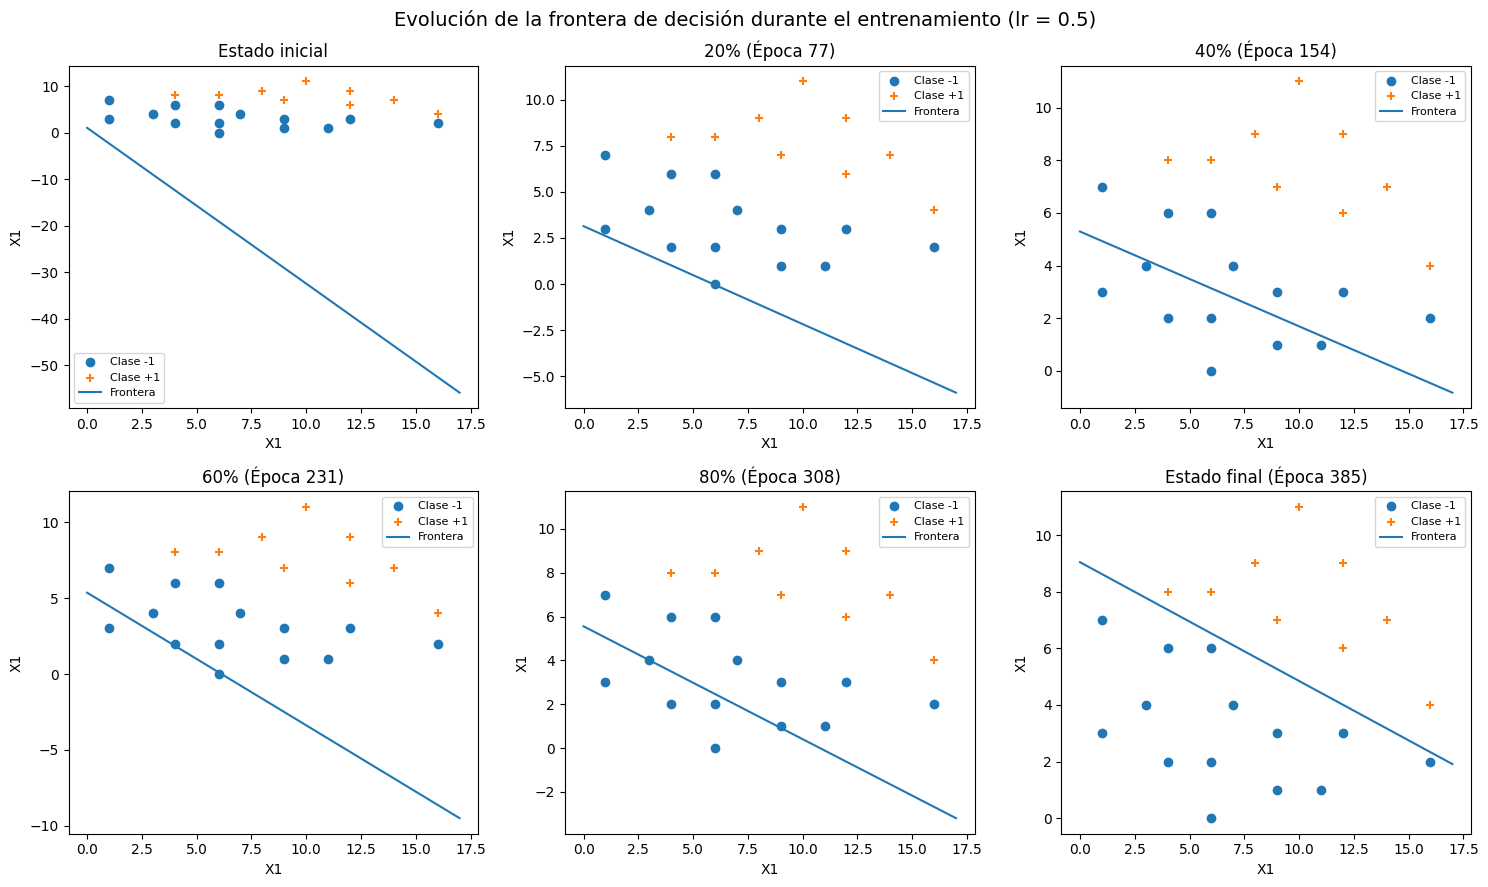

* comentario escrito sobre la evolución observada;

**Estado inicial:** La recta parte con una inclinación descendente marcada y desplazada hacia abajo respecto a los datos, sin separar las clases "-1" y "+1".

**20% (Época 17) y 40% (Época 34):** La frontera se desplaza hacia arriba y modifica su pendiente a medida que las actualizaciones corrigen errores de clasificación.

**60% (Época 51) y 80% (Época 68):** La recta sigue ajustando su altura y ángulo, acercándose cada vez más a la frontera real entre ambas clases.

**Estado final (Época 85):** La frontera de decisión queda ubicada de forma que separa correctamente las dos clases sin errores de clasificación.

* respuestas escritas a las preguntas guía.

### **Respuesta de la pregunta guía de la Actividad 7.a — Seis estados del entrenamiento**

A medida que se actualizan los pesos en cada época donde ocurre un error, la frontera de decisión cambia de posición e inclinación hasta encontrar una recta que separe ambas clases sin errores. Mientras se realizaba el entrenamiento, se presentaba ajustes escalonados cuando se corregian puntos mal clasificados, tendiendo de forma progresiva hacia una separación limpia a medida que avanzan las épocas hasta alcanzar el estado final con 0 errores.


### **Respuesta de la pregunta guía de la Actividad 7.b — Interpretación geométrica**

 La inclinación de la recta depende de la relación entre los pesos de las variables de entrada, en particular de cómo varían respecto a los valores de "X1" y "X2" durante las actualizaciones correspondientes. Además, el bias actúa como un término de desplazamiento de la recta respecto al origen: al actualizarse dentro del entorno correspondiente, permite mover la frontera hacia arriba o hacia abajo sin depender del valor de una característica de entrada, ayudando a que la recta se ubique correctamente entre las dos clases incluso cuando la frontera óptima no pasa por el origen.


# **Fase 8. Evolución del Error**

Además de observar la frontera de decisión, es necesario analizar cómo cambia el error durante el entrenamiento.

## **8.1 Actividades sobre el error**

### **Actividad 8.a — Gráfica de error**

Crea una función llamada plot_error(E_values, title) La función debe graficar:
* Eje X: época
* Eje Y: tasa de error
* Título
* Cuadrícula

Luego grafica la evolución del error para el entrenamiento con lr = 0.5.

**Pregunta guía:** ¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?

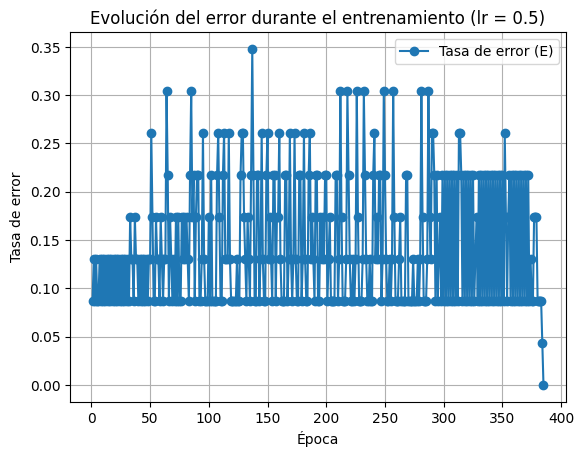

In [50]:
# Se importa matplotlib.pyplot para graficar la evolución de la tasa de error por época
import matplotlib.pyplot as plt
# Se define la función correspondiente
def plot_error(E_values, title):
  # Se verifica si la lista está vacía o es None antes de intentar gráficar
  if not E_values:
    print("La lista de valores está vacía")
    return
  # Se construye la secuencia de épocas para el eje "X"
  epocas = list(range(1, len(E_values) + 1))

  # Se crea una nueva figura para la gráfica de error
  plt.figure()
  # Se grafica la tasa de error en función del número de época
  plt.plot(epocas, E_values, marker = 'o', label = "Tasa de error (E)")
  # Se coloca la etiqueta del eje "X"
  plt.xlabel("Época")
  # Se coloca la etiqueta del eje "y"
  plt.ylabel("Tasa de error")
  # Se coloca el título recibido como parámetro
  plt.title(title)
  # Se activa la cuadrícula correspondiente
  plt.grid(True)
  # Se muestra la leyenda y la gráfica en pantalla
  plt.legend()
  plt.show()

# Se llama al error correspondiente
plot_error(E_values, "Evolución del error durante el entrenamiento (lr = 0.5)")

**RESPUESTA A LA PREGUNTA GUÍA:** No, el error en todas las épocas, porque el perceptrón actualiza los pesos instancia por instancia dentro de cada época. Al corregir un punto mal clasificado en un momento de la época, la frontera de decisión se mueve y puede hacer que otro punto pase al lado incorrecto en esa misma época o en la siguiente, haciendo que la tasa de error pueda aumentar temporalmente o mantenerse igual antes de converger a "0.0".

### **Actividad 8.b — Análisis de convergencia**

Observa la última época del entrenamiento.

**Pregunta guía:** ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta

**RESPUESTA A LA PREGUNTA GUÍA:** Que el error final sea igual a cero significa que el perceptrón logro clasificar correctamente el 100% de las instancias del conjunto de entrenamiento en la última época encontrando una frontera lineal que separa sin errores todos los datos con los que fue entrenado. Además, esta representación no significaría que el modelo sea perfecto para cualquier dato futuro porque un perceptrón solo tiene la capacidad para representar fronteras de decisión lineales; en caso de que los datos futuros presenten patrones no lineales, el modelo podrá separarlos perfectamente.

**Entregable de la Fase 8**

Al terminar, tu notebook debe contener:

* Función plot_error(E_values, title) implementada

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 8.a — Gráfica de error.

* Gráfica de evolución del error con lr = 0.5

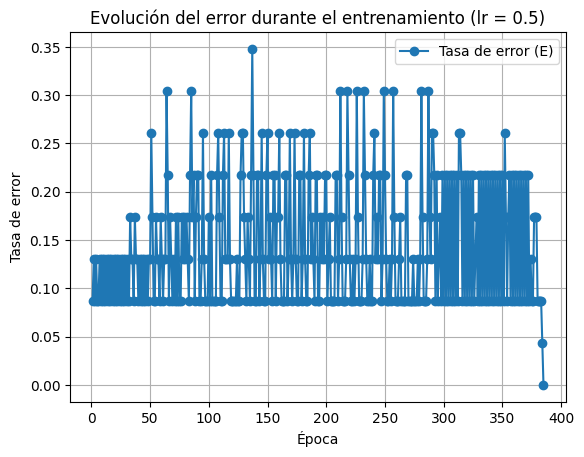

* Análisis escrito de la convergencia

En la gráfica anterior, se observa que el modelo logra converger antes de alcanzar el límite de 1000 épocas.

**Fase de ajustes:** Durante gran parte del entrenamiento la tasa de error oscila con picos cercanos a "0.30" y fluctuaciones entre distintos valores de error, debido a que los pesos se actualizan ante cada instancia mal clasificada dentro de cada época.

**Convergencia final:** En las últimas épocas del error, se evidencia un descenso hasta alcanzar "0.0" en la época "85", punto en el cual el perceptrón clasifica correctamente todas las instancias del dataset de entrenamiento y detiene el ciclo por "errores == 0".

* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 8.a — Gráfica de error**

No, el error no disminuye de forma continua en todas las épocas, porque el perceptrón actualiza los pesos instancia por instancia dentro de cada época. Al corregir un punto mal clasificado en un momento de la época, la frontera de decisión se mueve y puede hacer que otro punto pase al lado incorrecto en esa misma época o en la siguiente, haciendo que la tasa de error pueda aumentar temporalmente o mantenerse igual antes de converger a "0.0".

### **Respuesta de la pregunta guía de la Actividad 8.b — Análisis de convergencia**

Que el error final sea igual a cero significa que el perceptrón logro clasificar correctamente el 100% de las instancias del conjunto de entrenamiento en la última época encontrando una frontera lineal que separa sin errores todos los datos con los que fue entrenado. Además, esta representación no significaría que el modelo sea perfecto para cualquier dato futuro porque un perceptrón solo tiene la capacidad para representar fronteras de decisión lineales; en caso de que los datos futuros presenten patrones no lineales, el modelo no podrá separarlos perfectamente.

# **Fase 9. Comparación de Tasas de Aprendizaje**

La tasa de aprendizaje controla la magnitud de los cambios aplicados a los pesos cuando el perceptrón comete un error. En esta fase repetirás el entrenamiento con:
* lr = 0.3
* lr = 0.5
* lr = 0.8

Para que la comparación sea justa, debes usar los mismos pesos iniciales en los tres experimentos.

## **9.1 Actividades de comparación**

### **Actividad 9.a — Entrenamiento comparativo**

Inicializa un único vector de pesos iniciales y crea copias para cada valor de lr. Para cada tasa de aprendizaje, registra:
* Pesos finales
* Número de épocas
* Número total de actualizaciones
* Error final

**Pregunta guía:** ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?

In [55]:
# Se inicializa un único vector de pesos base
w_base = initialize_weights()
# Se definen las tres tasas de aprendizaje
tasas_aprendizaje = [0.3, 0.5, 0.8]
# Se crea un diccionario para guardar los resultados de cada tasa de aprendizaje
resultados_lr = {}
# Se muestra en consola el vector común de pesos iniciales
print("Pesos iniciales comunes (w_base): ", w_base)
print("=" * 60)
# Se recorre cada tasa de aprendizaje para entfrenar el perceptrón de manera independiente
for lr in tasas_aprendizaje:
  # Se crea una copia nueva para que este experimento no modifique el vector base
  w_inicial_copia = list(w_base)
  # Se crea una copia nueva para que este experimento no modifique el vector base
  w_fin, epocas, actualizaciones, W_hist, E_hist = perceptron_learning(X, y, w_inicial_copia, lr = lr, max_epochs = 1000)
  # Se calcula el error final tomando el último valor registrado en E_hist
  error_fin = E_hist[-1]
  # Se almacena los datos relevantes de este experimento en el diccionario correspondiente
  resultados_lr[lr] = {
      "w_inicial": w_inicial_copia,
      "w_final": w_fin,
      "epocas": epocas,
      "actualizaciones": actualizaciones,
      "error_final": error_fin,
      "w_values": W_hist,
      "E_values": E_hist,
  }
  # Se muestran en consola los resultados solicitados para esta tasa de aprendizaje
  print(f"Tasa de aprendizaje (lr = {lr}:)")
  print(f"- Pesos finales: ", w_fin)
  print(f"- Número de épocas: ", epocas)
  print(f"- Número total de actualizaciones: ", actualizaciones)
  print(f"- Error final: ", error_fin)
  print("-" * 60)

Pesos iniciales comunes (w_base):  [-0.4784503655990199, 0.08051875661737495, -0.06396390694943432]
Tasa de aprendizaje (lr = 0.3:)
- Pesos finales:  [-34.678450365599055, 1.280518756617382, 4.136036093050543]
- Número de épocas:  103
- Número total de actualizaciones:  309
- Error final:  0.0
------------------------------------------------------------
Tasa de aprendizaje (lr = 0.5:)
- Pesos finales:  [-57.478450365599016, 2.080518756617373, 6.936036093050568]
- Número de épocas:  103
- Número total de actualizaciones:  309
- Error final:  0.0
------------------------------------------------------------
Tasa de aprendizaje (lr = 0.8:)
- Pesos finales:  [-91.67845036559896, 3.2805187566173717, 11.136036093050516]
- Número de épocas:  103
- Número total de actualizaciones:  309
- Error final:  0.0
------------------------------------------------------------


**RESPUESTA A LA PREGUNTA GUÍA:** Porque los pesos iniciales determinan el punto de partida de la frontera de decisión en el plano y cuántas instancias inician mal clasificadas. Si cada tasa de aprendizaje comenzara desde un vector de pesos distinto, las diferencias en el número de épocas o de actualizaciones podrían deberse a un punto de partida más beneficiosos o más perjudicial, y no al efecto real de la tasa de aprendizaje "lr".

### **Actividad 9.b — Gráficas comparativas**

Para cada valor de lr, genera:
* seis gráficas de evolución de la frontera;
* gráfica de evolución del error.

**Pregunta guía:** ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?

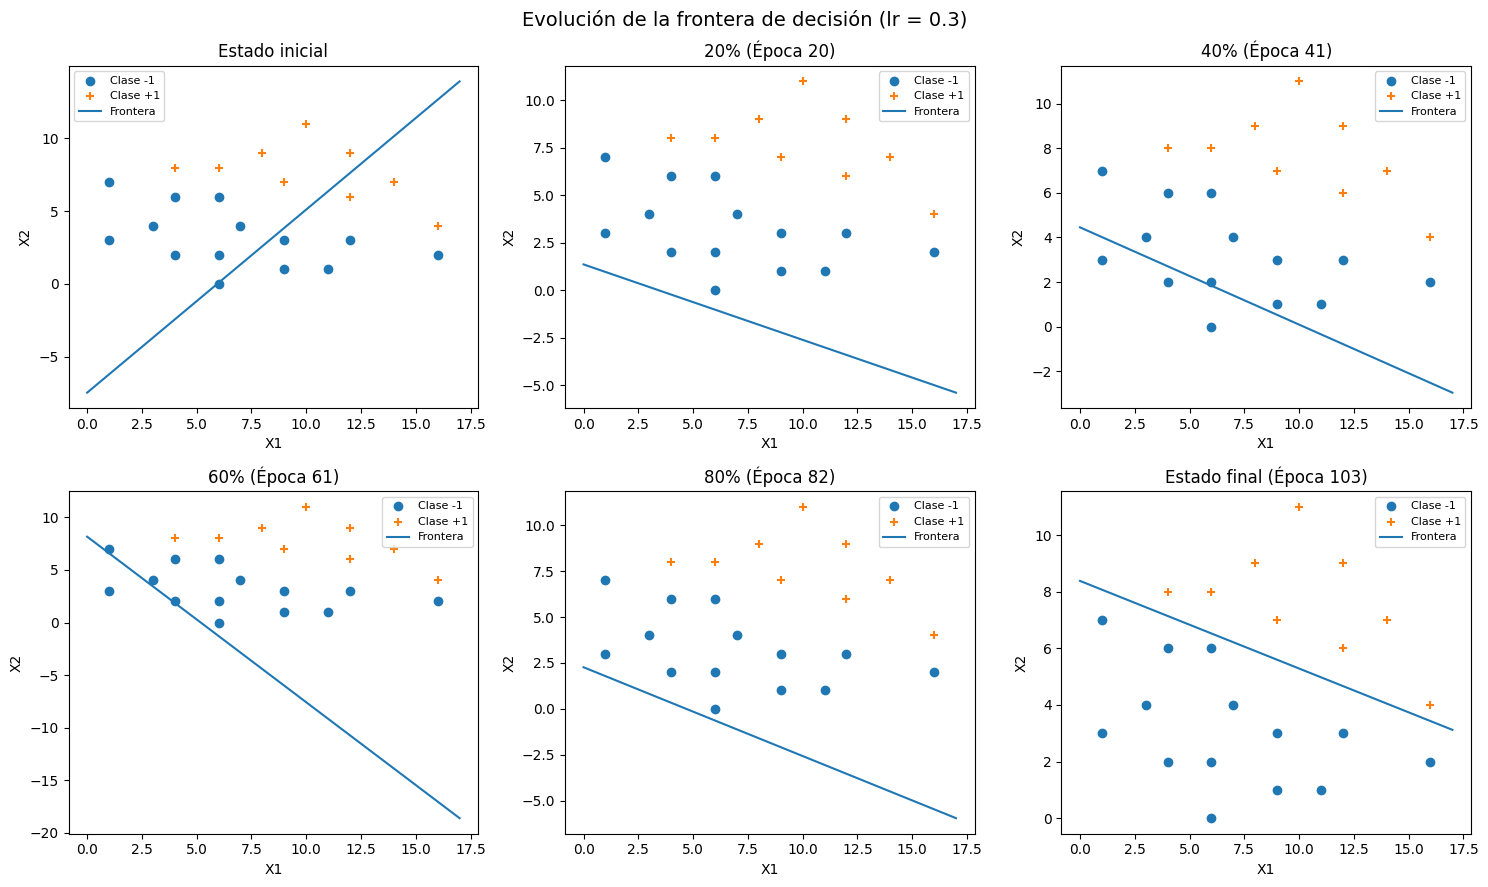

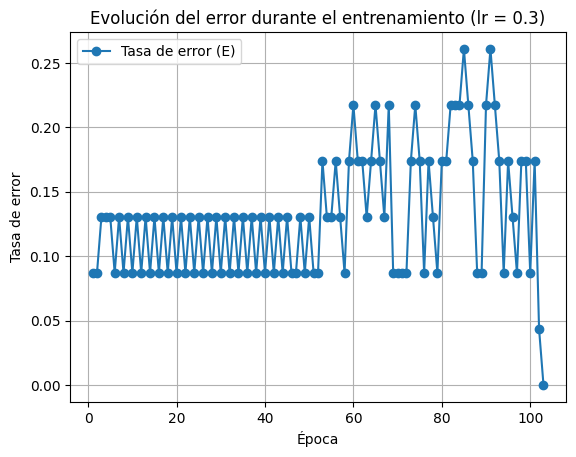

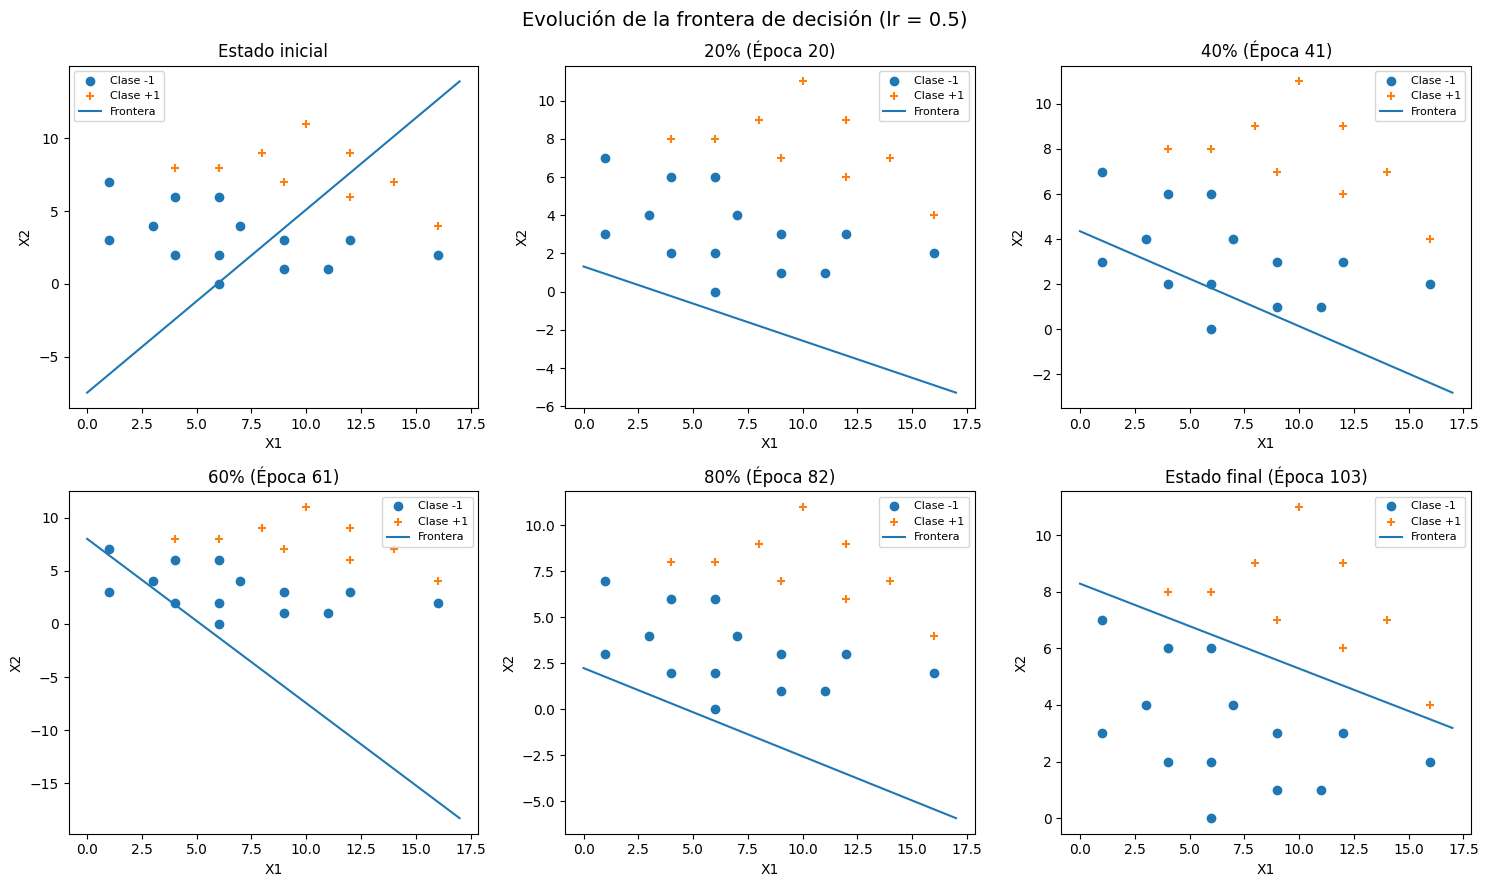

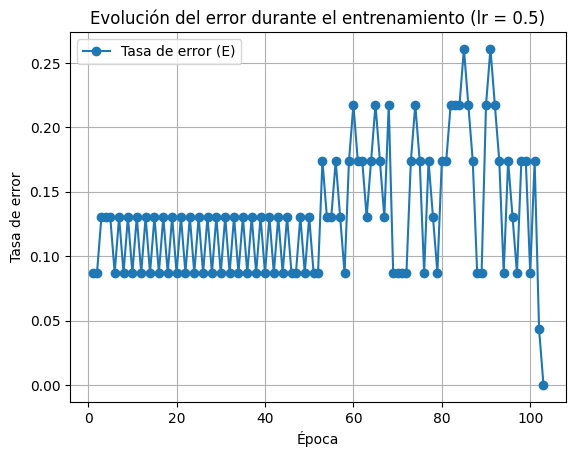

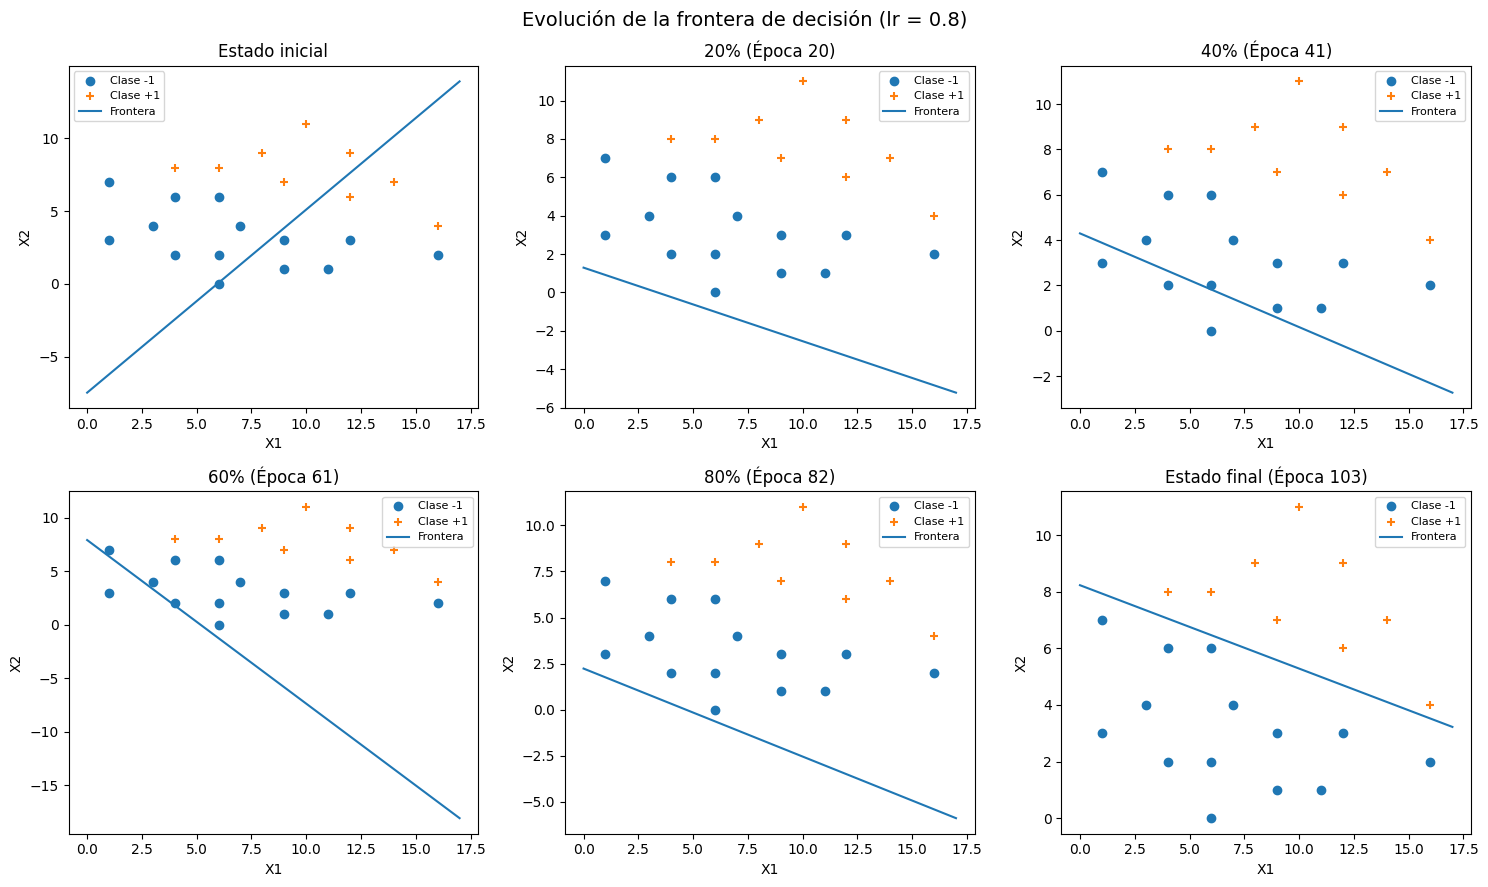

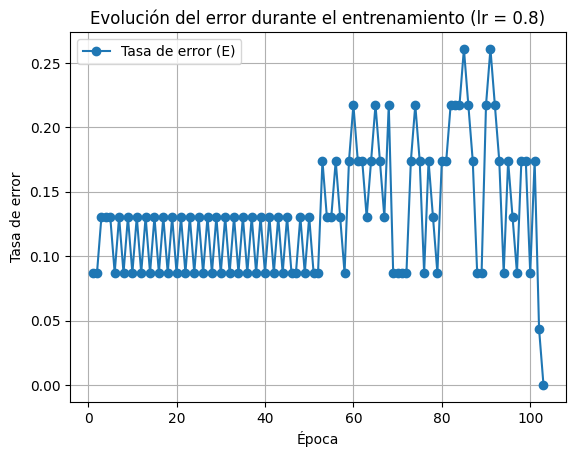

In [58]:
# Se importa matplotlib.pyplot para graficar los 6 estados de la frontera de decisión
import matplotlib.pyplot as plt

def graficar_seis_estados(X, y, W_ini, W_hist, titulo_general):
  # Se separa las coordenadas de X1 y X2 según la clase real (-1 o +1) del dataset
  x1_neg = []
  x2_neg = []
  x1_pos = []
  x2_pos = []
  todos_x1 = []
  # Se recorre todas las instancias del dataset para clasificar sus coordenadas visuales
  for i in range(len(X)):
    x1_val = X[i][0]
    x2_val = X[i][1]
    etiqueta = y[i]
    todos_x1.append(x1_val)
    if etiqueta == -1:
      x1_neg.append(x1_val)
      x2_neg.append(x2_val)
    elif etiqueta == 1:
      x1_pos.append(x1_val)
      x2_pos.append(x2_val)
  # Se definen los límites horizontales con un margen de una unidad
  x1_min = min(todos_x1) - 1
  x1_max = max(todos_x1) + 1
  # Se obtiene el total de épocas registradas en W_hist
  total_epocas_hist = len(W_hist)
  # Se calculan los índices correspondientes para los respectivos porcentajes del entrenamiento
  if total_epocas_hist < 6:
    estados = [("Inicial", list(W_ini))]
    for i in range(total_epocas_hist):
      estados.append((f"Época {i + 1}", W_hist[i]))
  else:
    # Se calcula los índices aproximados para 20%, 40%, 60% y 80% del entrenamiento
    i_20 = max(0, min(total_epocas_hist - 1, int(0.2 * total_epocas_hist) - 1))
    i_40 = max(0, min(total_epocas_hist - 1, int(0.4 * total_epocas_hist) - 1))
    i_60 = max(0, min(total_epocas_hist - 1, int(0.6 * total_epocas_hist) - 1))
    i_80 = max(0, min(total_epocas_hist - 1, int(0.8 * total_epocas_hist) - 1))
    # Se arma la lista con los 6 estados solicitados
    estados = [
        ("Estado inicial", list(W_ini)),
        (f"20% (Época {i_20 + 1})", W_hist[i_20]),
        (f"40% (Época {i_40 + 1})", W_hist[i_40]),
        (f"60% (Época {i_60 + 1})", W_hist[i_60]),
        (f"80% (Época {i_80 + 1})", W_hist[i_80]),
        (f"Estado final (Época {total_epocas_hist})", W_hist[-1]),
    ]
  # Se crea una figura con cuadrícula de 2 filas y 3 columnas
  fig, axes = plt.subplots(2, 3, figsize=(15, 9))
  # Se recorre cada uno de los estados seleccionados para graficarlo en su subgráfico
  for k in range(len(estados)):
    fila = k // 3
    col = k % 3
    ax = axes[fila, col]
    nombre_estado, w_estado = estados[k]
    w0 = w_estado[0]
    w1 = w_estado[1]
    w2 = w_estado[2]
    # Se grafica los puntos de ambas clases
    ax.scatter(x1_neg, x2_neg, marker="o", label="Clase -1")
    ax.scatter(x1_pos, x2_pos, marker="+", label="Clase +1")
    # Se traza la frontera de decisión según el valor de w2 para evitar división por cero
    if w2 != 0:
      x2_min = -(w0 + w1 * x1_min) / w2
      x2_max = -(w0 + w1 * x1_max) / w2
      ax.plot([x1_min, x1_max], [x2_min, x2_max], label="Frontera")
    else:
      if w1 != 0:
        x1_vertical = -w0 / w1
        ax.axvline(x=x1_vertical, label="Frontera (w2 = 0)")
      else:
        ax.text(
            0.5,
            0.5,
            "Sin frontera definida",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )

    ax.set_title(nombre_estado)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend(loc="best", fontsize=8)

  # Si hubo menos de 6 estados disponibles, ocultamos los subgráficos sobrantes
  for j in range(len(estados), 6):
    fila = j // 3
    col = j % 3
    axes[fila, col].axis("off")

  plt.suptitle(titulo_general, fontsize=14)
  plt.tight_layout()
  plt.show()


# Se recorren las tres tasas de aprendizaje para generar las gráficas de cada una
for lr in [0.3, 0.5, 0.8]:
  datos = resultados_lr[lr]
  # Se grafican los 6 estados de evolución de la frontera para este valor de lr
  graficar_seis_estados(
      X,
      y,
      datos["w_inicial"],
      datos["w_values"],
      f"Evolución de la frontera de decisión (lr = {lr})",
  )
  plot_error(
      datos["E_values"],
      f"Evolución del error durante el entrenamiento (lr = {lr})",
  )

**RESPUESTA A LA PREGUNTA GUÍA:** En esta ejecución, ninguna tasa de aprendizaje destacó por usar menos épocas que las otras: lr = 0.3, lr = 0.5 y lr = 0.8 convergieron en la misma cantidad de épocas (103 épocas), alcanzando una tasa de error de 0.0 en el estado final. Converger en menos épocas en una ejecución específica no garantiza que esa tasa sea siempre la mejor en todos los escenarios. Una tasa de aprendizaje muy alta puede dar pasos grandes que provoquen oscilaciones o sobrepasar soluciones con buen margen en problemas más complejos. Mientras que una tasa moderada o más pequeña realiza ajustes más graduales y estables, lo que suele ser preferible cuando se busca un comportamiento más controlado en otros conjuntos de datos.

### **Actividad 9.c — Tabla comparativa**

Construye una tabla como la siguiente:

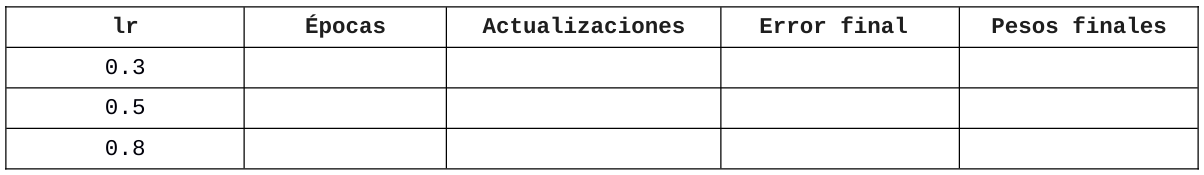

**Pregunta guía:** ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?

In [59]:
print(f"{'lr':<6} {'Épocas':<8} {'Actualizaciones':<17} {'Error final':<13} {'Pesos finales'}")
print("-" * 95)
# Se recorre cada tasa de aprendizaje y se imprime su fila con los resultados obtenidos
for lr in [0.3, 0.5, 0.8]:
  datos = resultados_lr[lr]
  # Se redondean los pesos finales a 4 decimales para facilitar la lectura en consola
  pesos_redondeados = [round(p,4) for p in datos["w_final"]]
  # Se redondea el error final a 4 decimales
  error_redondeado = round(datos["error_final"], 4)
  # Se imprime una fila alineada por columna
  print(f"{lr:<6} {datos['epocas']:<8} {datos['actualizaciones']:<17} {error_redondeado:<13} {pesos_redondeados}")

lr     Épocas   Actualizaciones   Error final   Pesos finales
-----------------------------------------------------------------------------------------------
0.3    103      309               0.0           [-34.6785, 1.2805, 4.136]
0.5    103      309               0.0           [-57.4785, 2.0805, 6.936]
0.8    103      309               0.0           [-91.6785, 3.2805, 11.136]


**RESPUESTA A LA PREGUNTA GUÍA:** Los pesos finales no son necesariamente iguales para las tres tasas de aprendizaje, porque el tamaño del paso en cada actualización depende de "lr", lo que genera trayectorias distintas de actualización y detiene el algoritmo en cuanto se alcanzan "0" errores en una época. No se puede procudir una clasificación correcta porque no existe una única recta ni un único vector de pesos que separe ambas clases sin errores: cualquier combinación de pesos que defina una frontera lineal ubicada entre las dos clases clasificará correctamente las instancias de entrenamiento.

**Entregable de la Fase 9**

Al terminar, tu notebook debe contener:

* Entrenamientos con lr = 0.3, lr = 0.5 y lr = 0.8

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 9.a — Entrenamiento comparativo.

* Tabla comparativa

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 9.c — Tabla comparativa.

* Gráficas de frontera para cada tasa de aprendizaje

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 9.b — Gráficas comparativas.

* Gráficas de error para cada tasa de aprendizaje

**Nota importante:** El código ya se encuentra desarrollado en esta actividad. Para ello, debe dirigirse a la parte de Actividad 9.b — Gráficas comparativas.

* Respuestas escritas a las preguntas guía

### **Respuesta de la pregunta guía de la Actividad 9.a — Entrenamiento comparativo.**

Porque los pesos iniciales determinan el punto de partida de la frontera de decisión en el plano y cuántas instancias inician mal clasificadas. Si cada tasa de aprendizaje comenzara desde un vector de pesos distinto, las diferencias en el número de épocas o de actualizaciones podrían deberse a un punto de partida más beneficiosos o más perjudicial, y no al efecto real de la tasa de aprendizaje "lr".

### **Respuesta de la pregunta guía de la Actividad 9.b — Gráficas comparativas.**

En esta ejecución, ninguna tasa de aprendizaje destacó por usar menos épocas que las otras: lr = 0.3, lr = 0.5 y lr = 0.8 convergieron en la misma cantidad de épocas (103 épocas), alcanzando una tasa de error de 0.0 en el estado final. Converger en menos épocas en una ejecución específica no garantiza que esa tasa sea siempre la mejor en todos los escenarios. Una tasa de aprendizaje muy alta puede dar pasos grandes que provoquen oscilaciones o sobrepasar soluciones con buen margen en problemas más complejos. Mientras que una tasa moderada o más pequeña realiza ajustes más graduales y estables, lo que suele ser preferible cuando se busca un comportamiento más controlado en otros conjuntos de datos.

### **Respuesta de la pregunta guía de la Actividad 9.c — Tabla comparativa.**

Los pesos finales no son necesariamente iguales para las tres tasas de aprendizaje, porque el tamaño del paso en cada actualización depende de "lr", lo que genera trayectorias distintas de actualización y detiene el algoritmo en cuanto se alcanzan "0" errores en una época. No se puede procudir una clasificación correcta porque no existe una única recta ni un único vector de pesos que separe ambas clases sin errores: cualquier combinación de pesos que defina una frontera lineal ubicada entre las dos clases clasificará correctamente las instancias de entrenamiento.

# **RESULTADOS OBTENIDOS:**
**1.** Se implementó manualmente el perceptrón, incluyendo inicialización de pesos, función de activación bipolar, cálculo de salida y regla de actualización sin utilizar librerías de machine learning.

**2.** El modelo logró aprender una frontera de decisión lineal capaz de separar las dos clases del dataset, evidenciando la relación entre pesos, bias y recta de clasificación.

**3.** Se registró y visualizó la evolución del entrenamiento mediante gráficas de frontera de decisión y curvas de error, observando cómo los pesos modifican geométricamente la separación entre clases.

**4.** Se compararon distintas tasas de aprendizaje (0.3, 0.5 y 0.8), identificando su influencia en el número de épocas, actualizaciones realizadas, estabilidad del entrenamiento y pesos finales obtenidos.

# **CONCLUSIONES:**

**1.** Cada estudiante debe agregar al menos una conclusión propia derivada de sus observaciones específicas.

A lo largo de esta práctica sobre el perceptrón simple implementada en Python puro y Matplotlib sin emplear librerías de aprendizaje automático externas, se comprobó de manera práctica cómo funciona una neurona artificial desde su base matemática hasta su entrenamiento iterativo a través de la combinación ponderada de las entradas, la función de activación escalón bipolar y la regla de actualización de pesos ante cada error, haciendo que el modelo logre ajustar progresivamente su frontera de decisión lineal sobre el conjunto de datos bidimensional.

# **REFERENCIAS:**

**[1]** F. Rosenblatt, “The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain,” Psychological Review, vol. 65, no. 6, pp. 386–408, 1958.

**[2]** W. S. McCulloch and W. Pitts, “A Logical Calculus of the Ideas Immanent in Nervous Activity,” Bulletin of Mathematical Biophysics, vol. 5, pp. 115–133, 1943.

**[3]** H. Ortega Martínez, Machine Learning Workout: with exercises and practicals in MATLAB. Quito: Editorial Abya-Yala / Universidad Politécnica Salesiana, 2019, ISBN 978-9978-10-394-4. [En línea]. Disponible en: https://dspace.ups.edu.ec/handle/123456789/19046